In [1]:
from astropy.io import fits
from astropy.time import Time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta

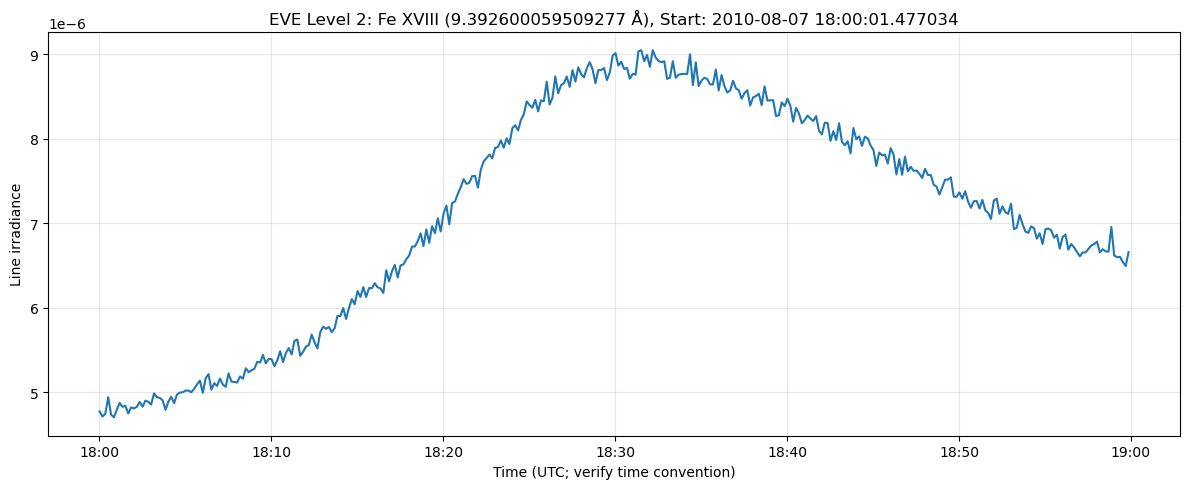

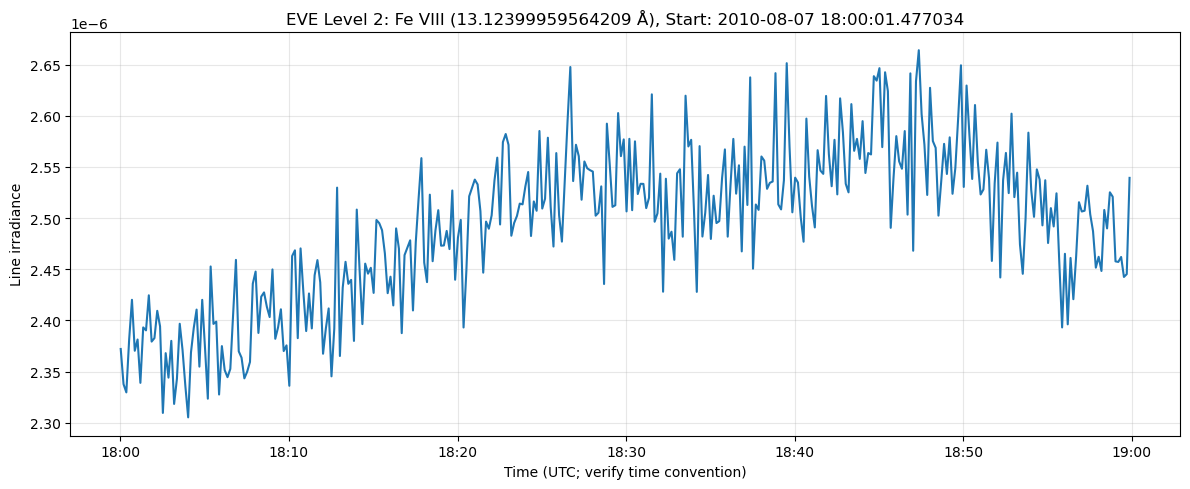

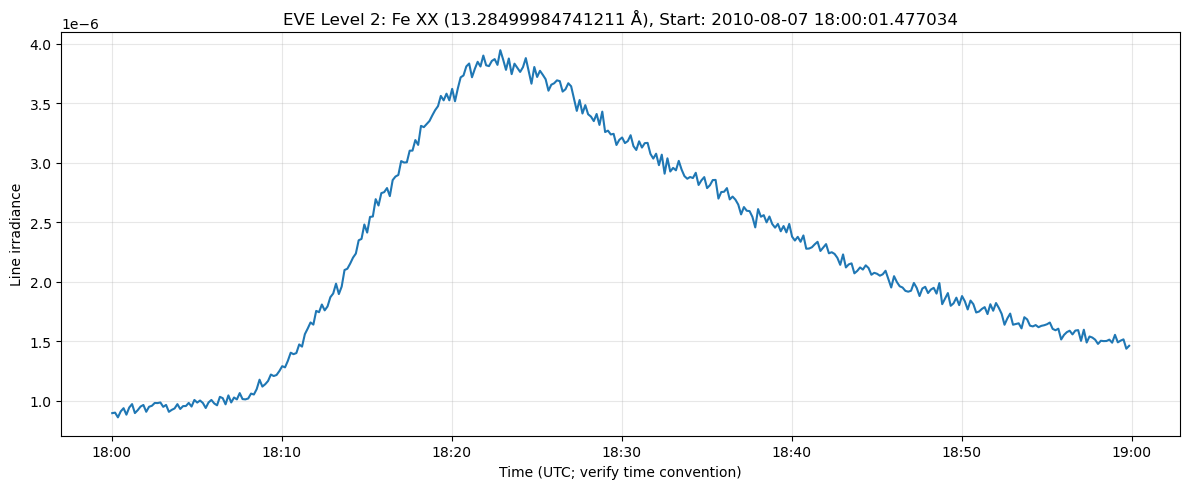

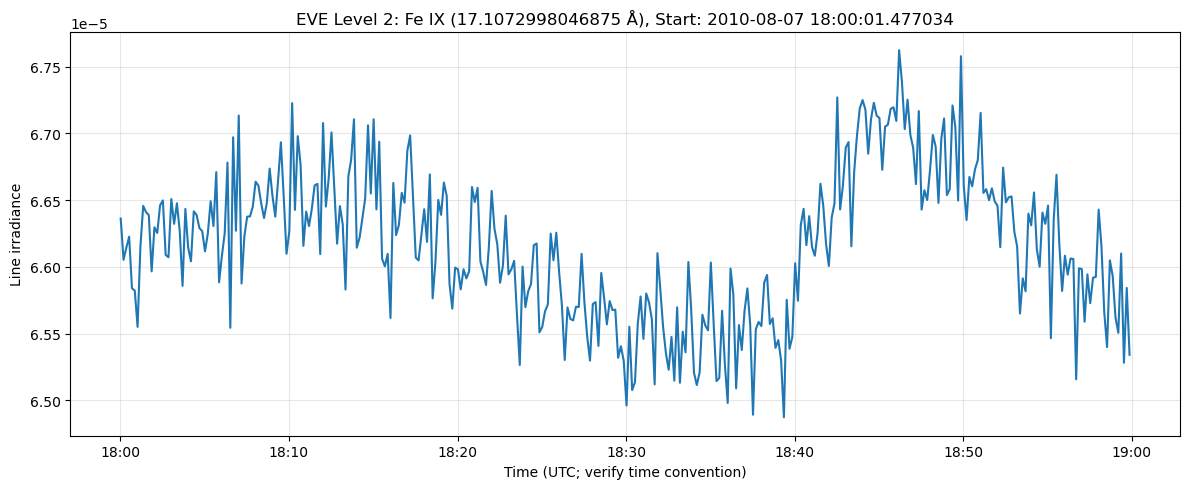

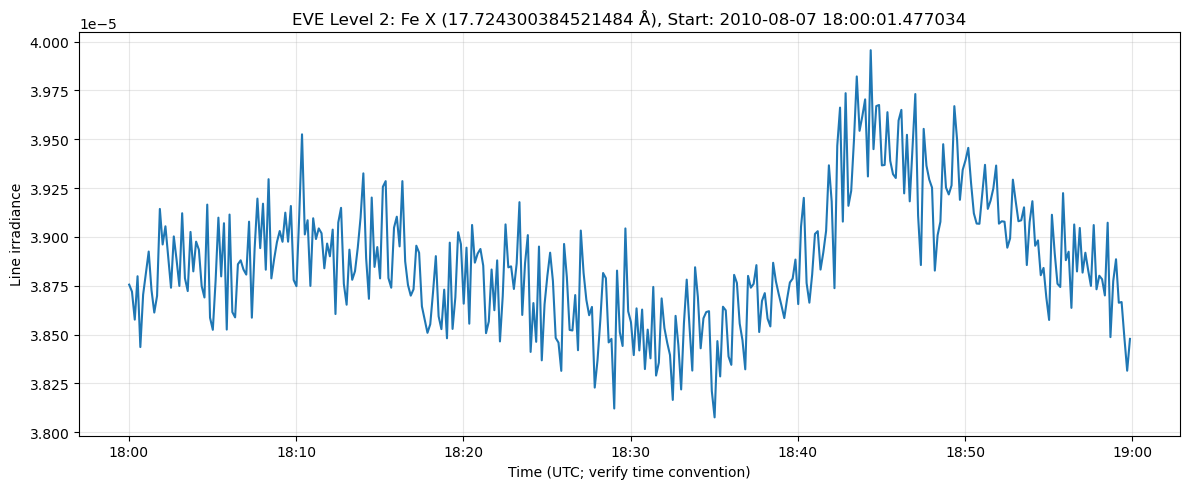

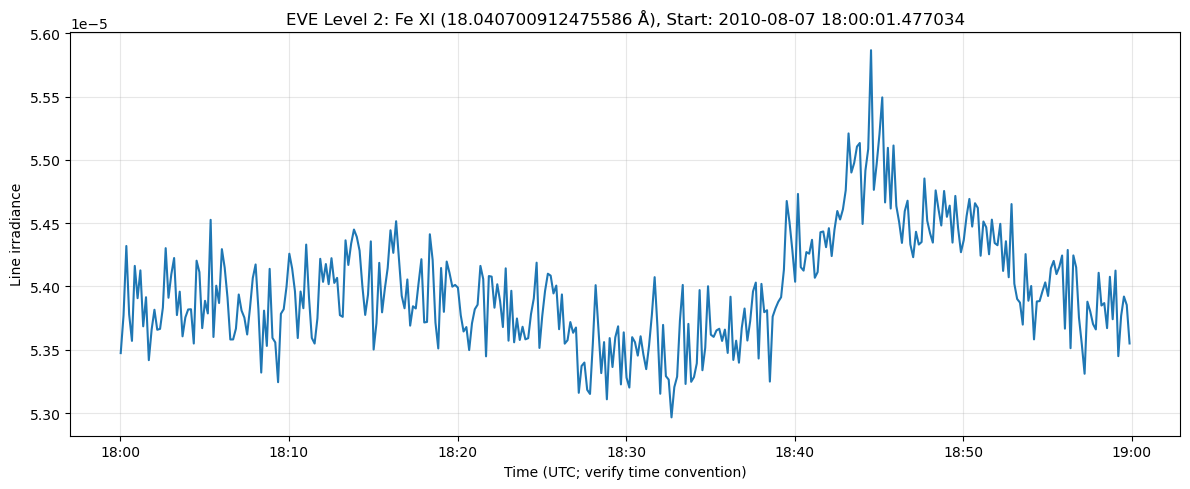

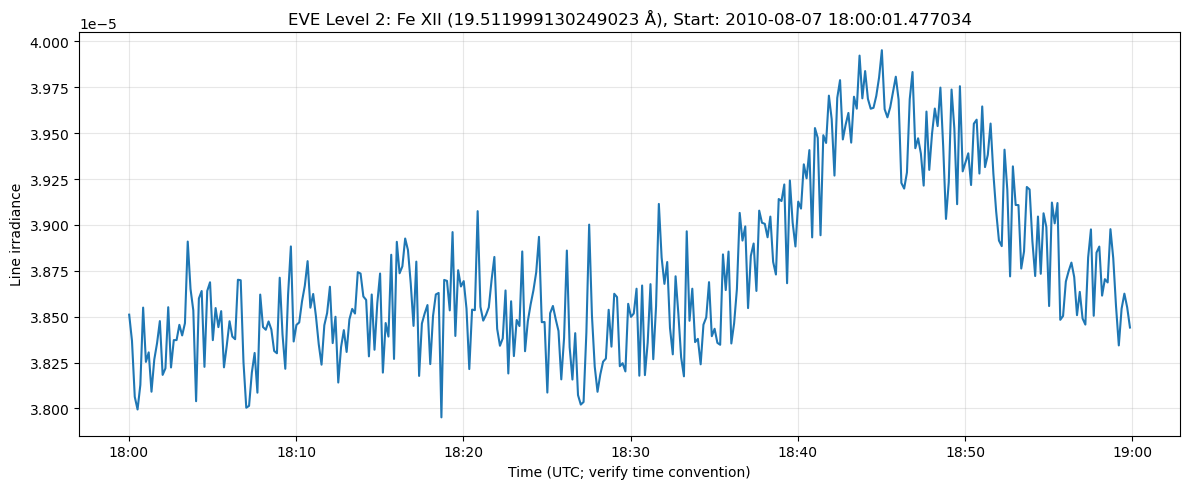

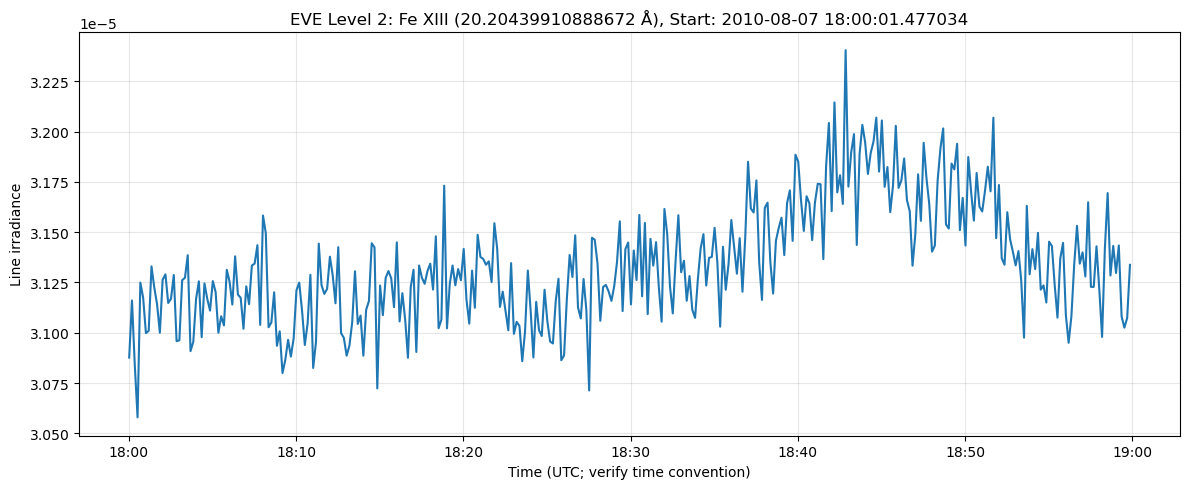

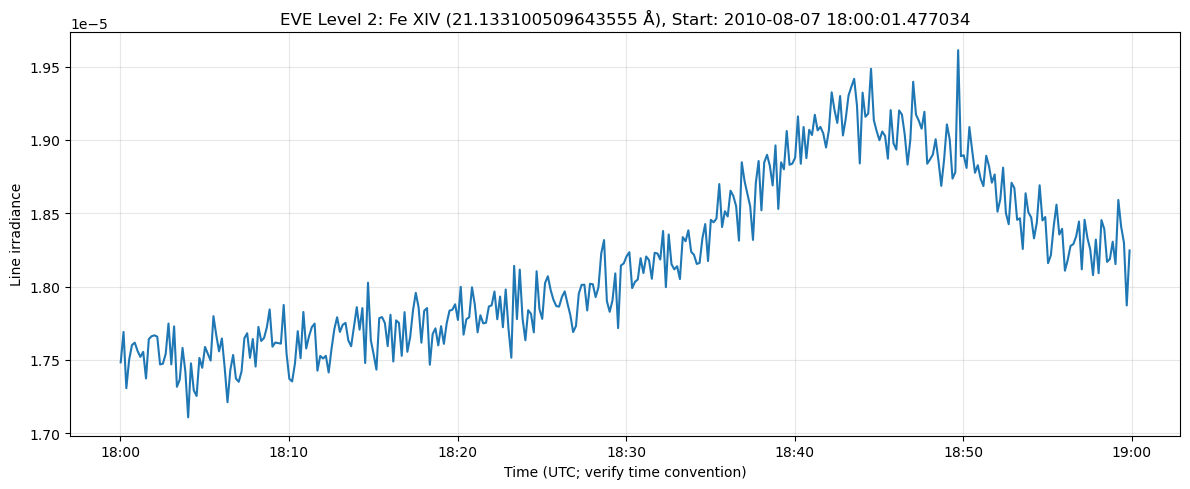

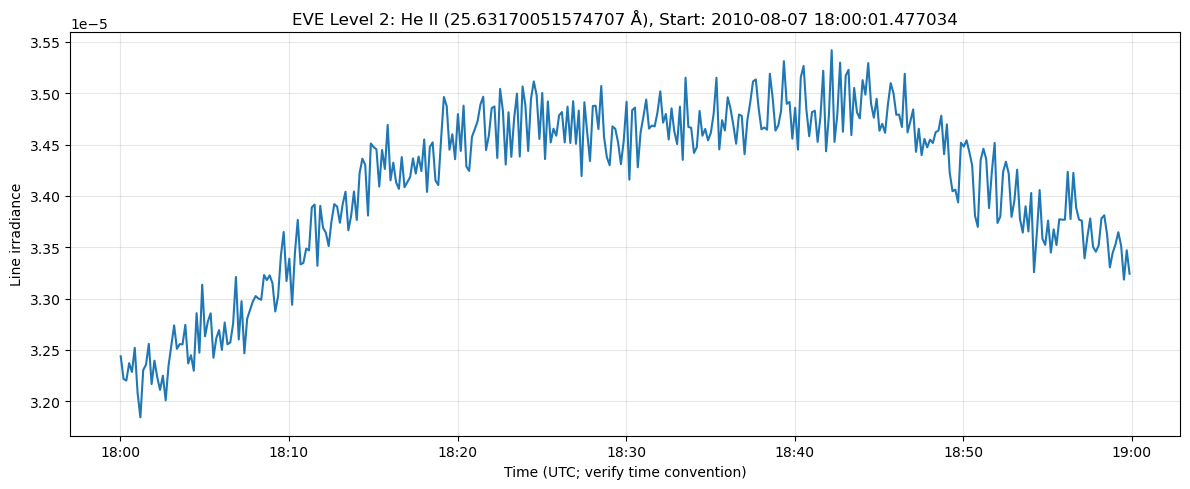

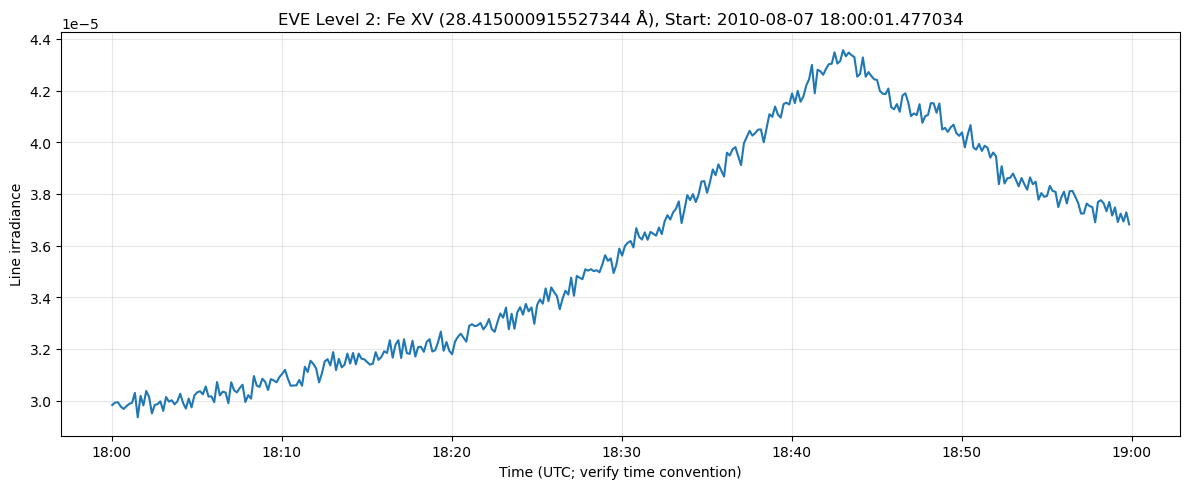

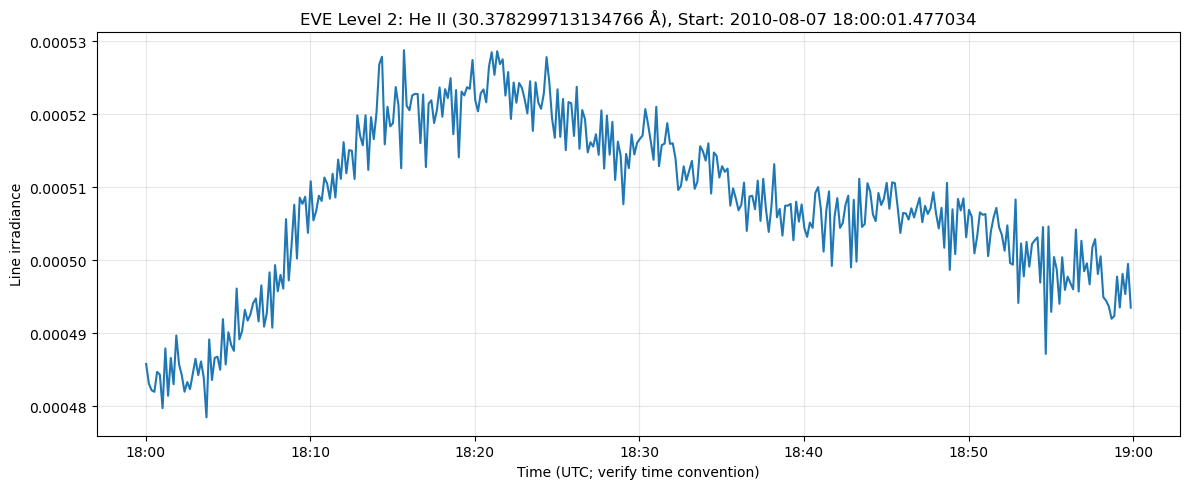

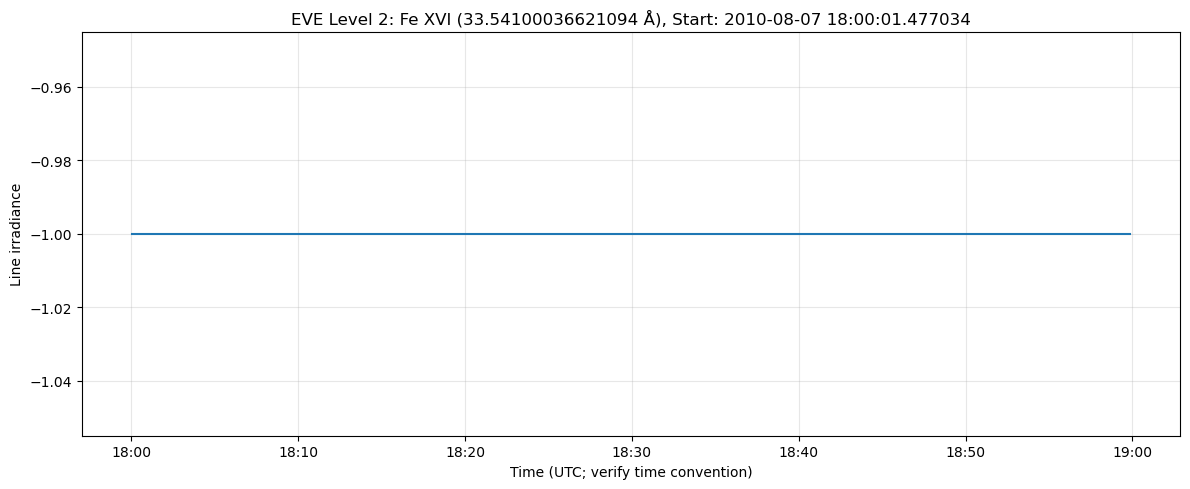

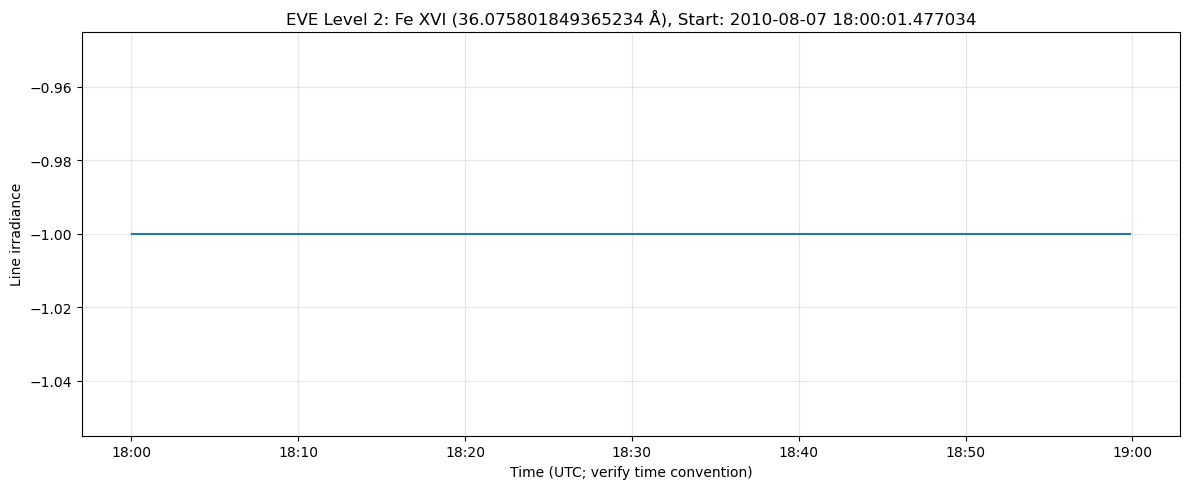

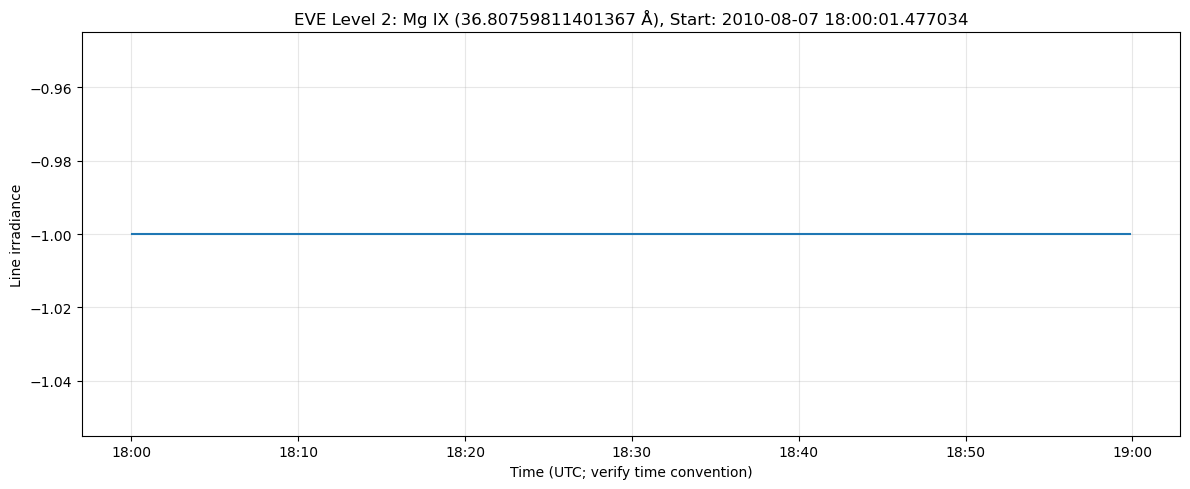

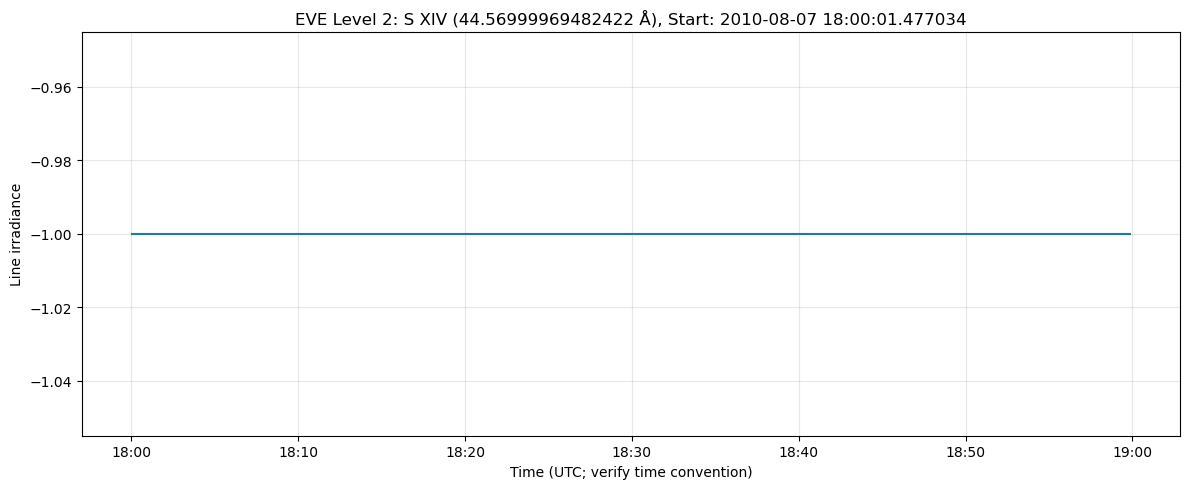

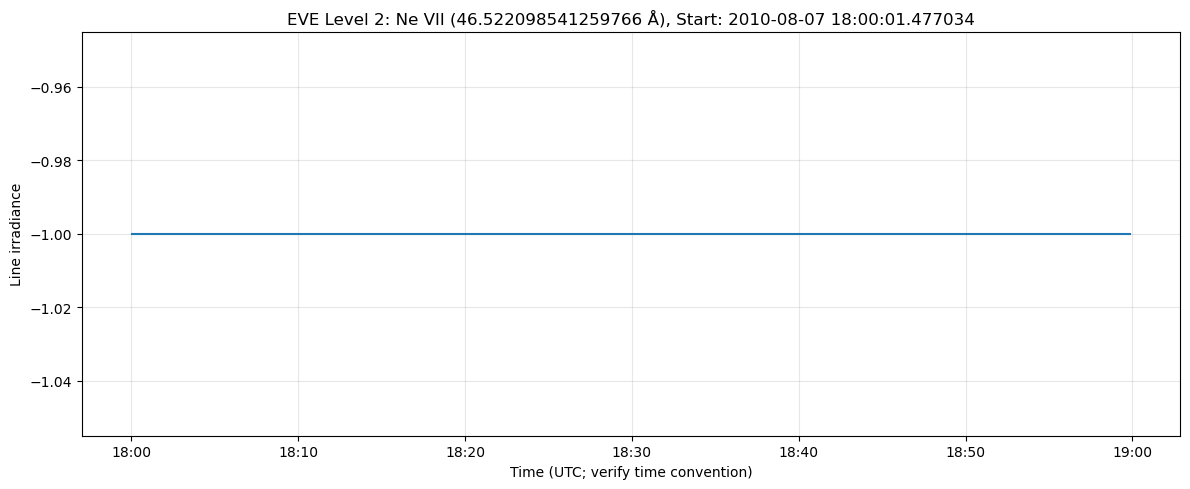

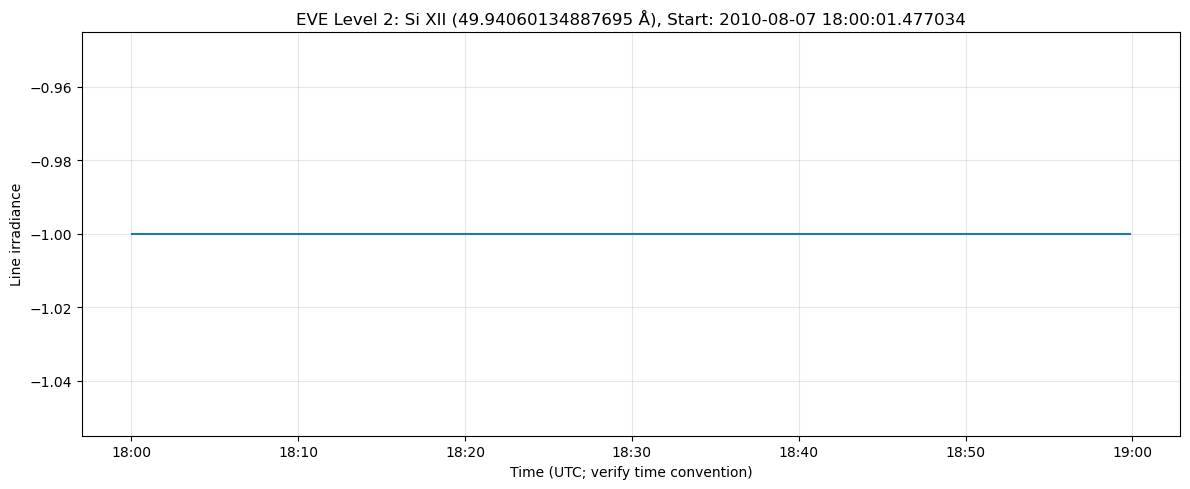

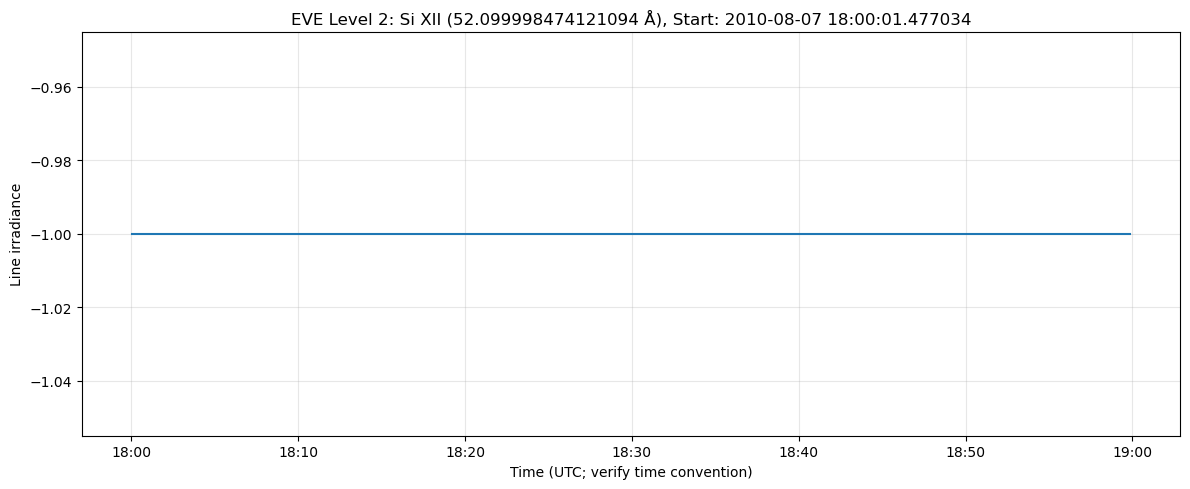

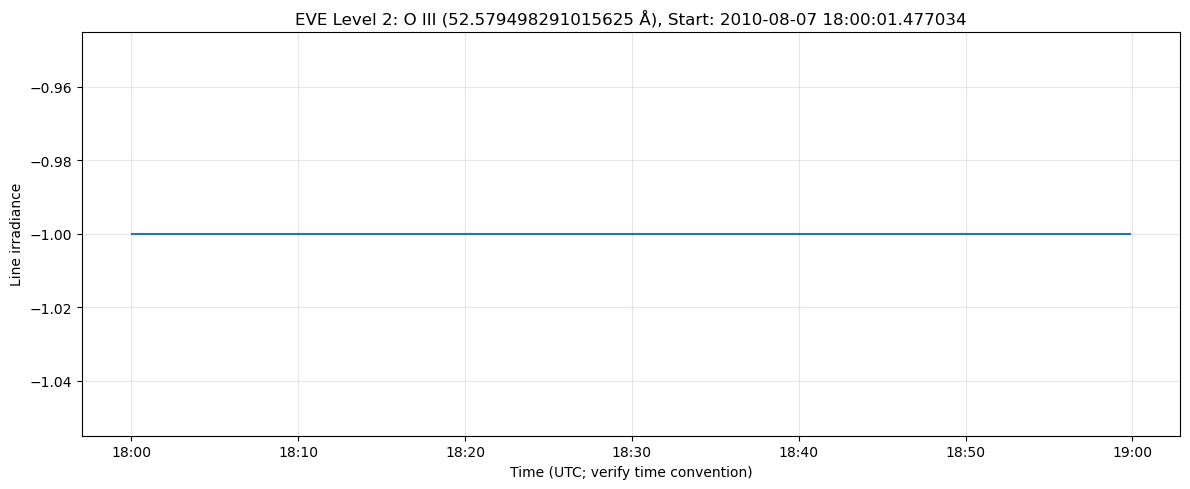

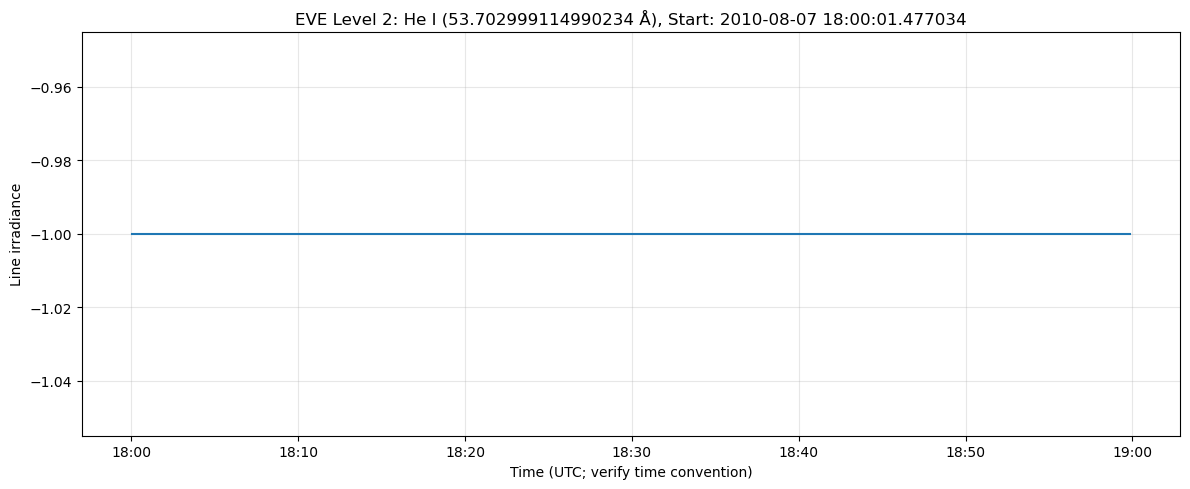

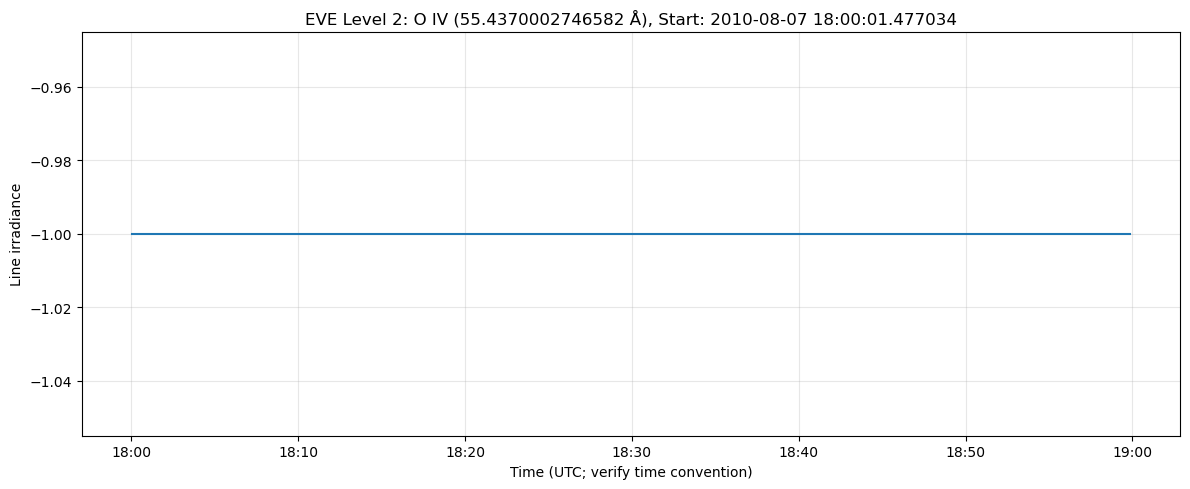

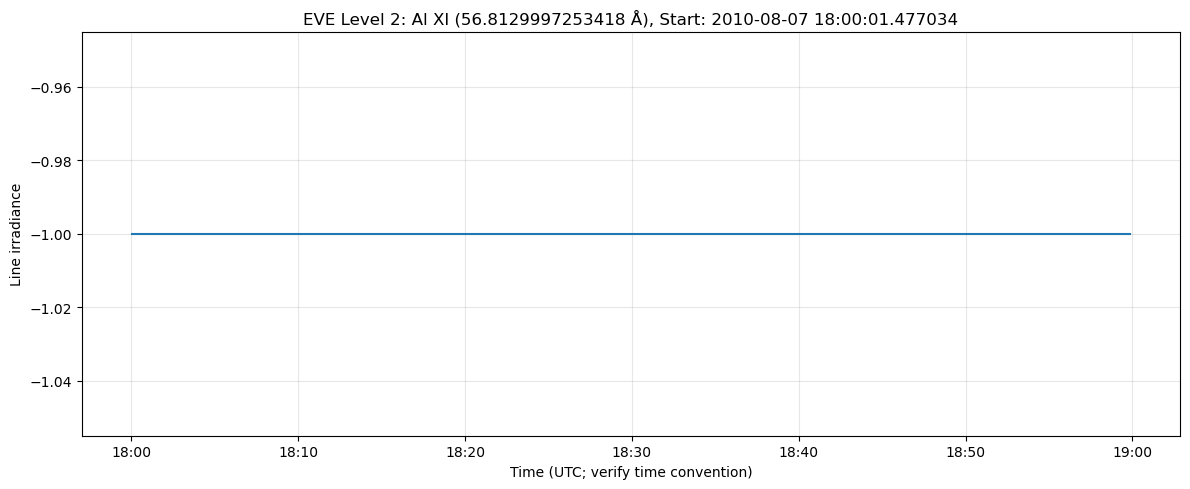

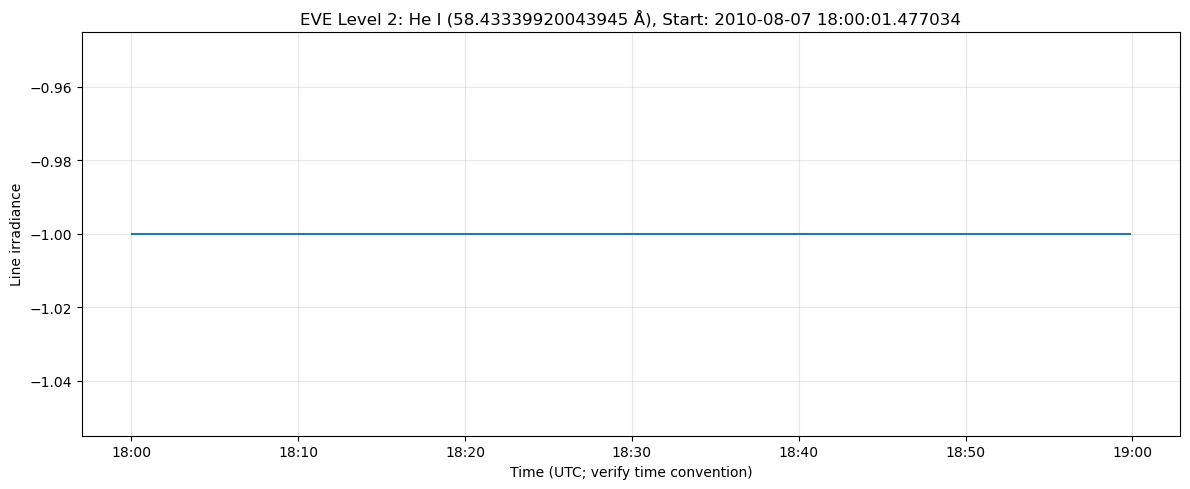

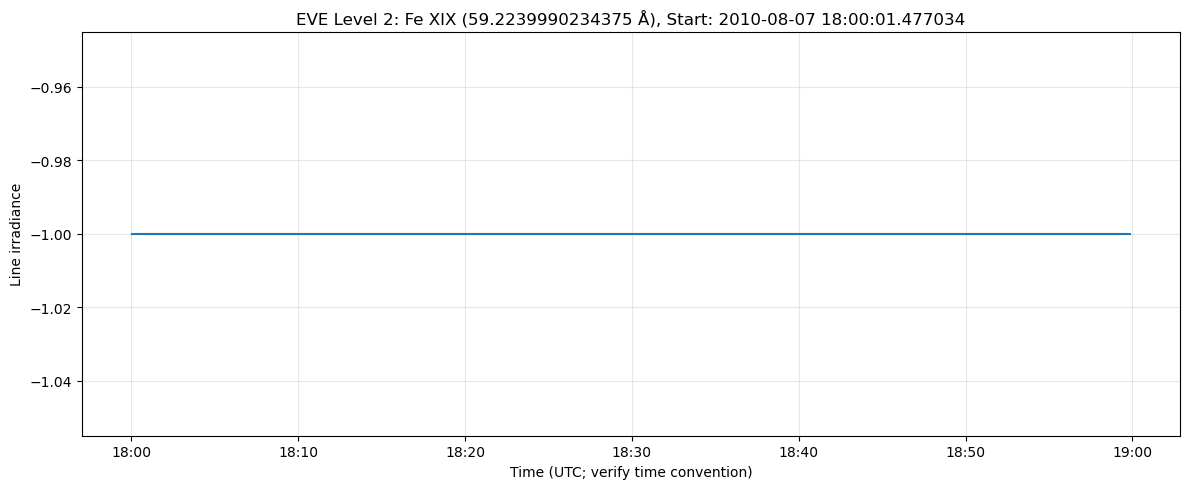

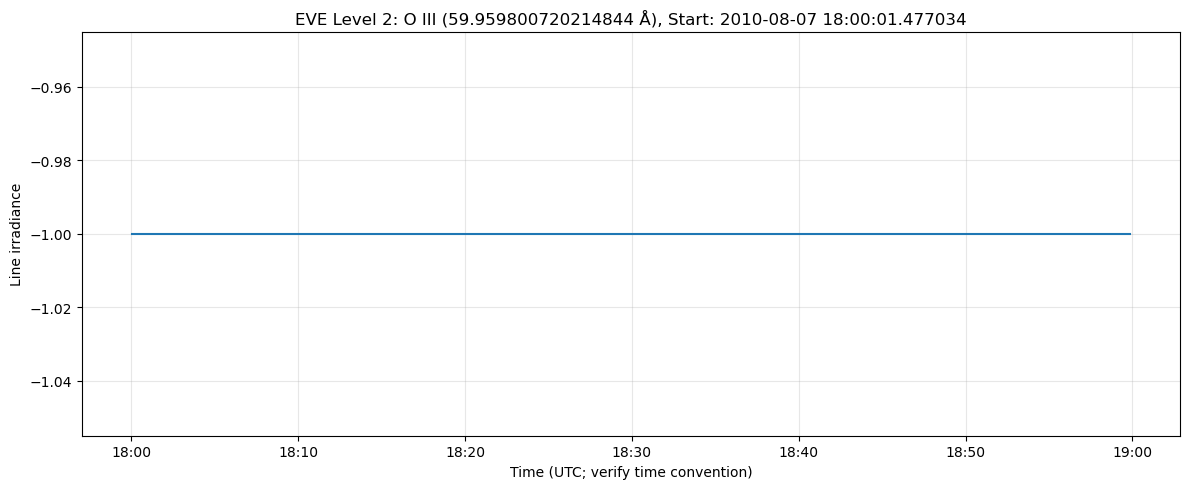

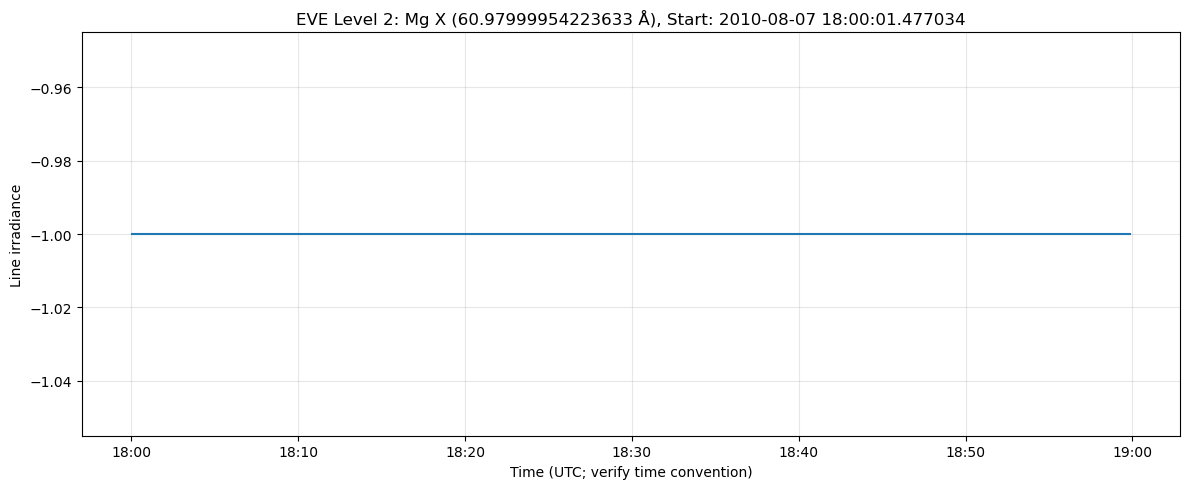

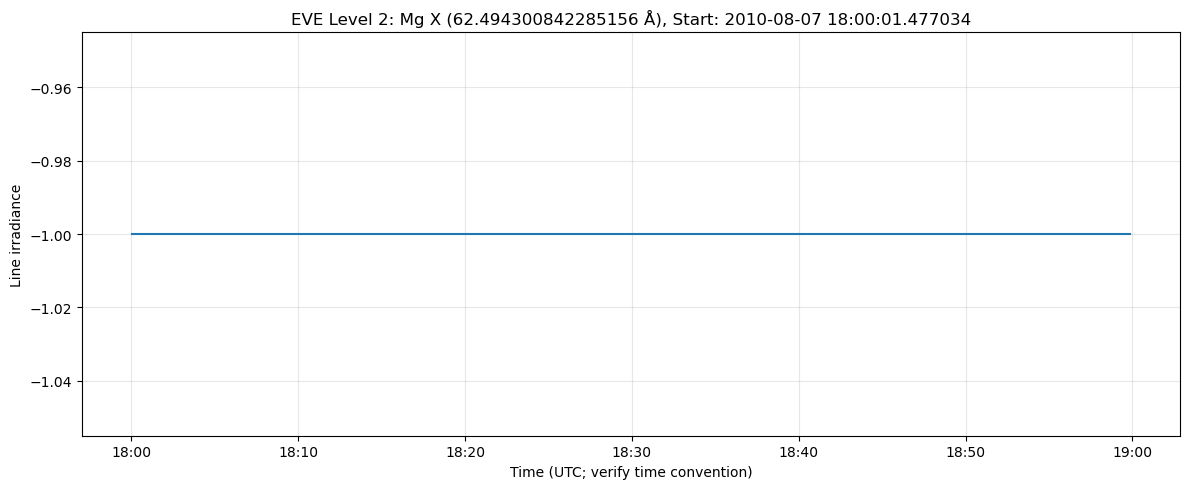

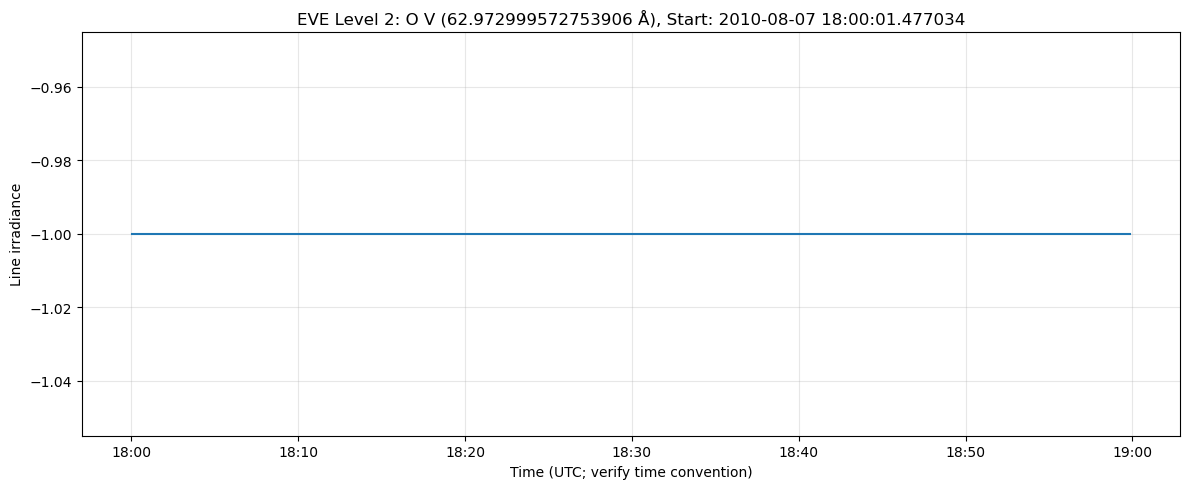

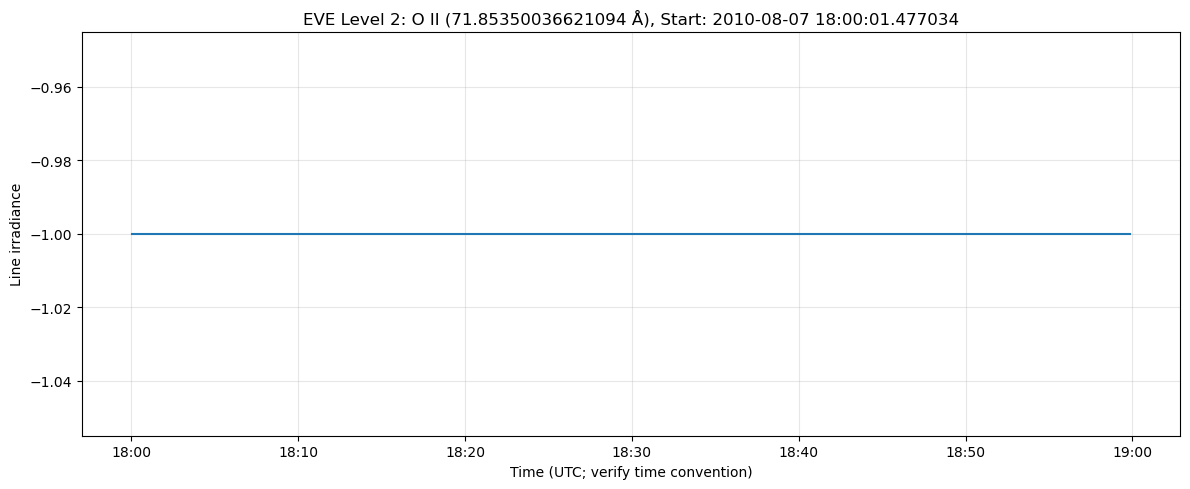

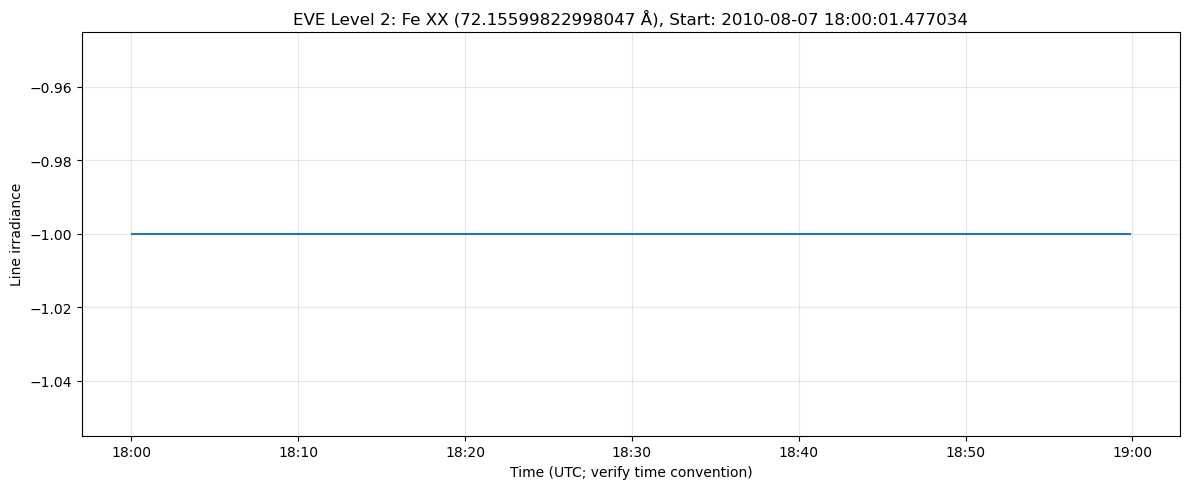

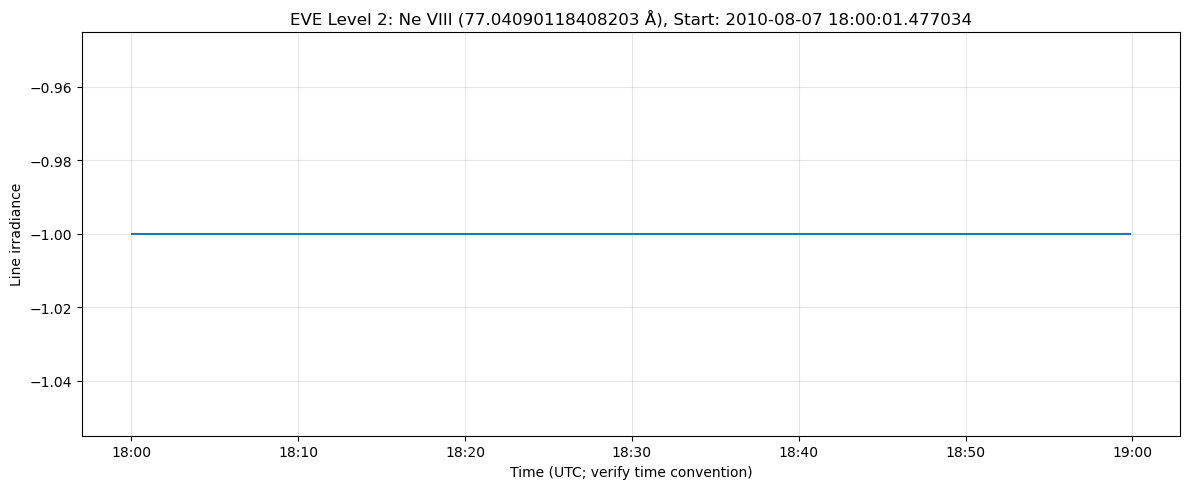

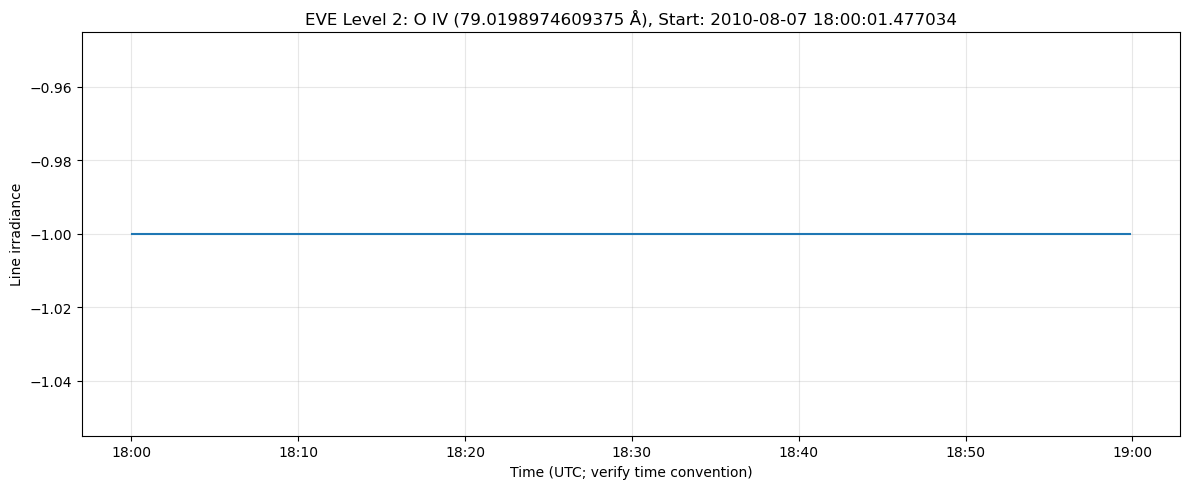

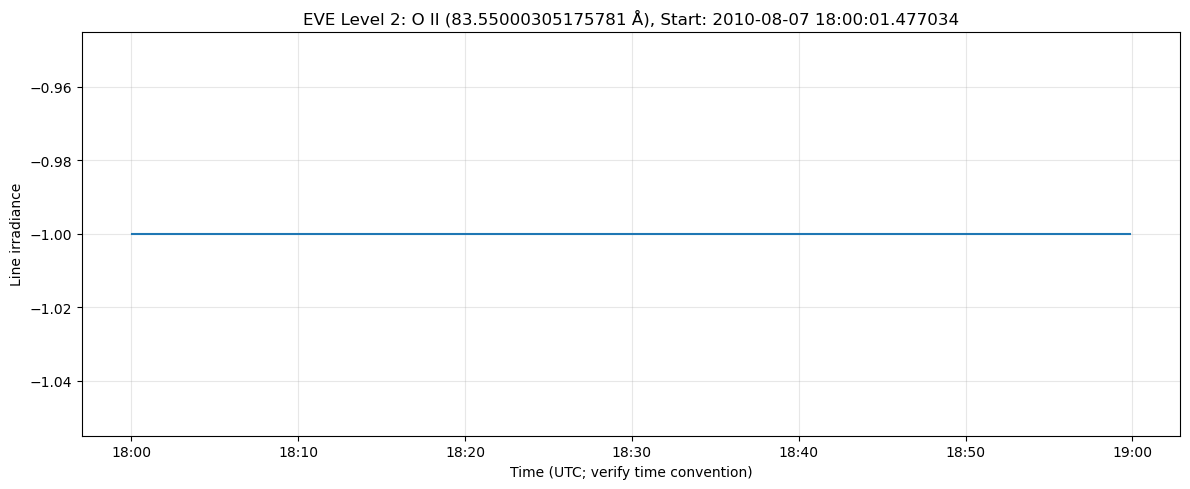

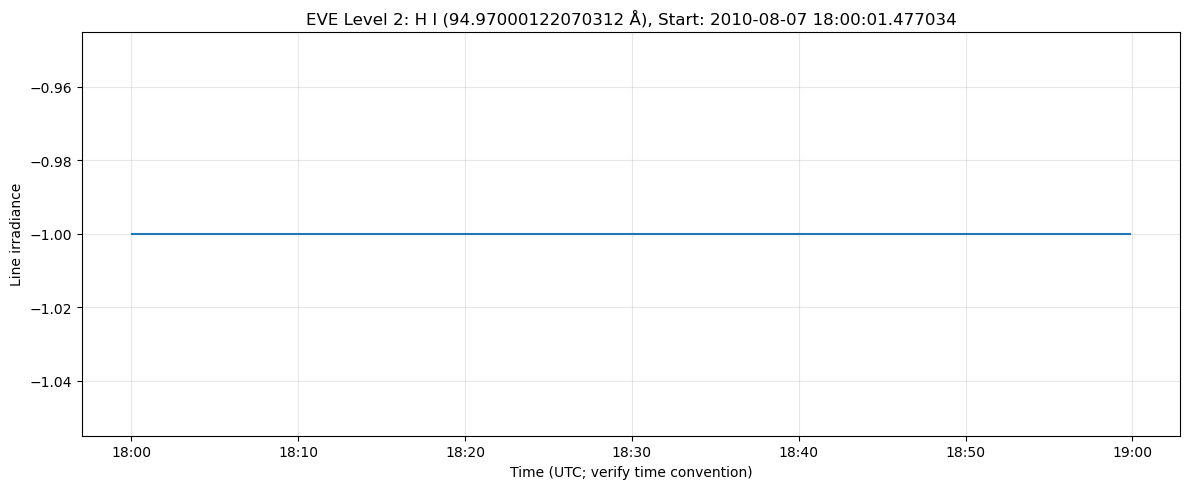

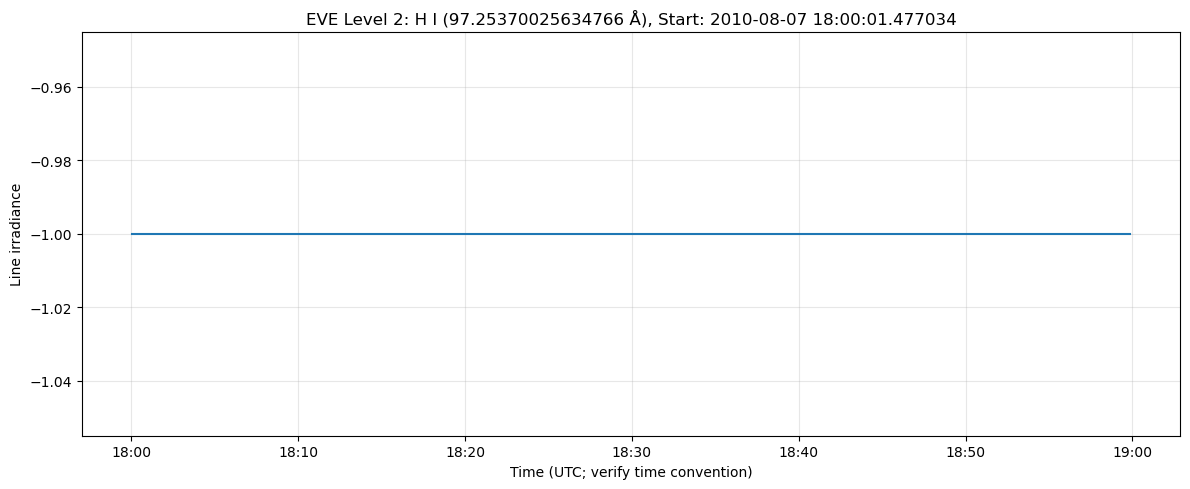

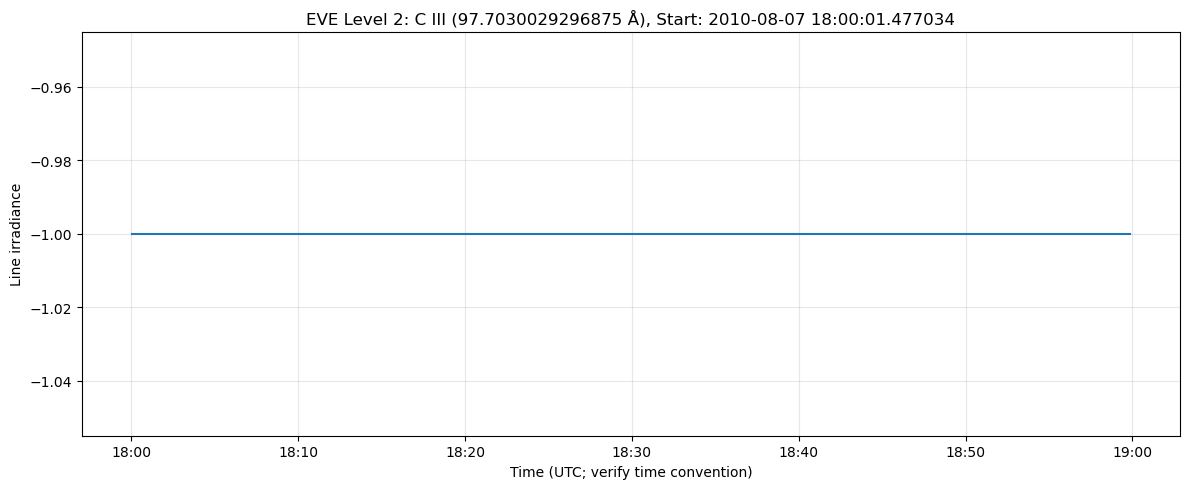

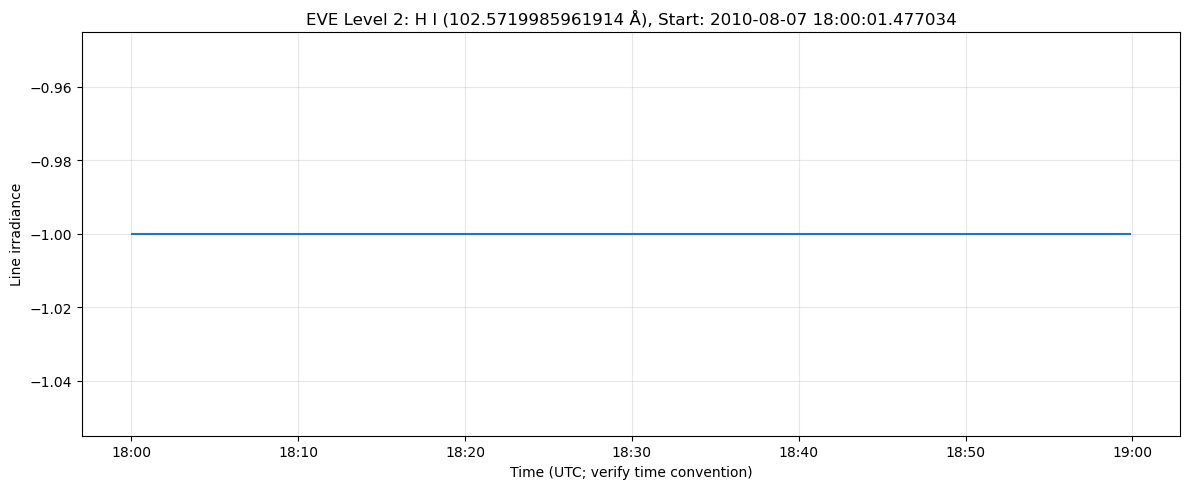

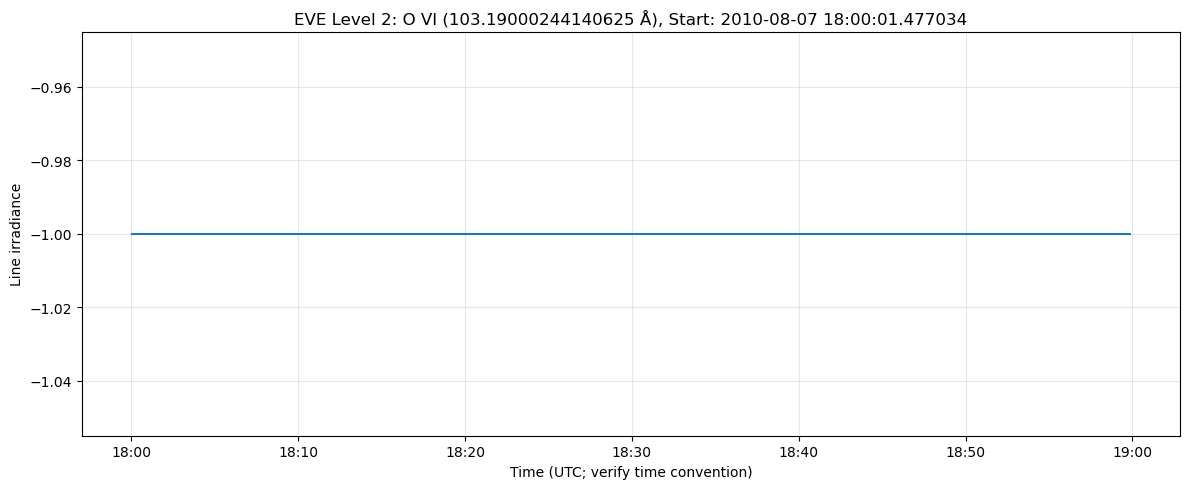

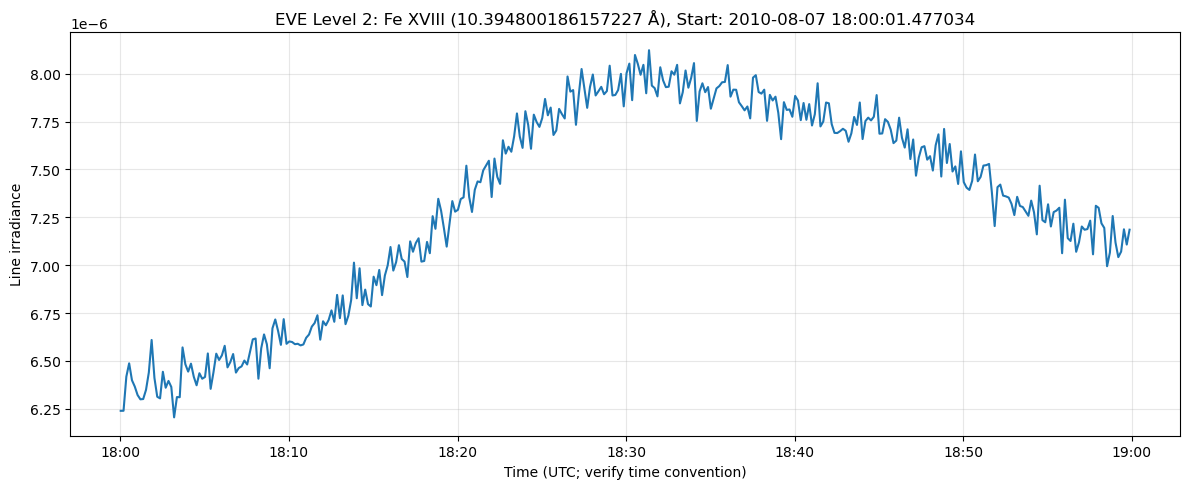

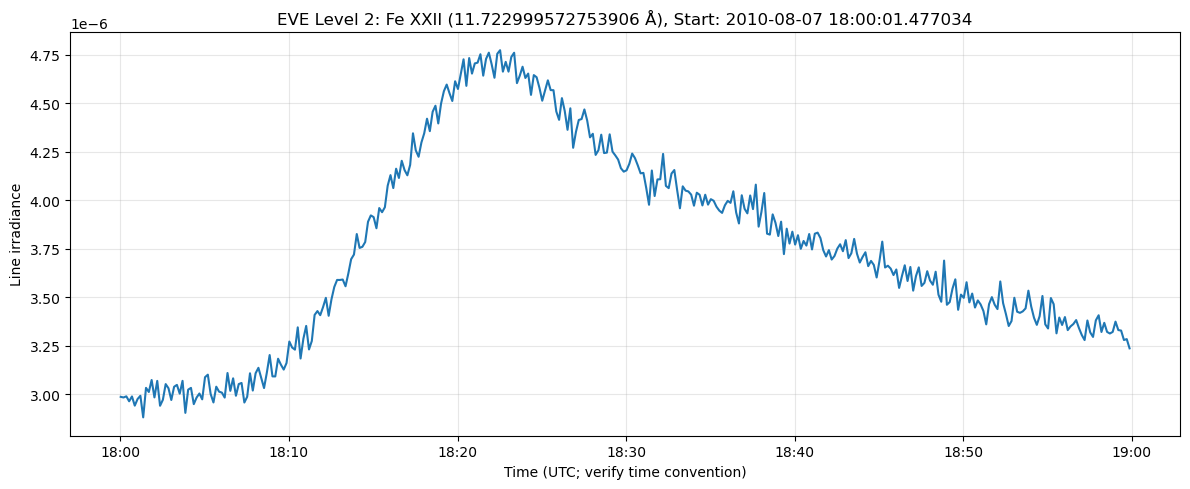

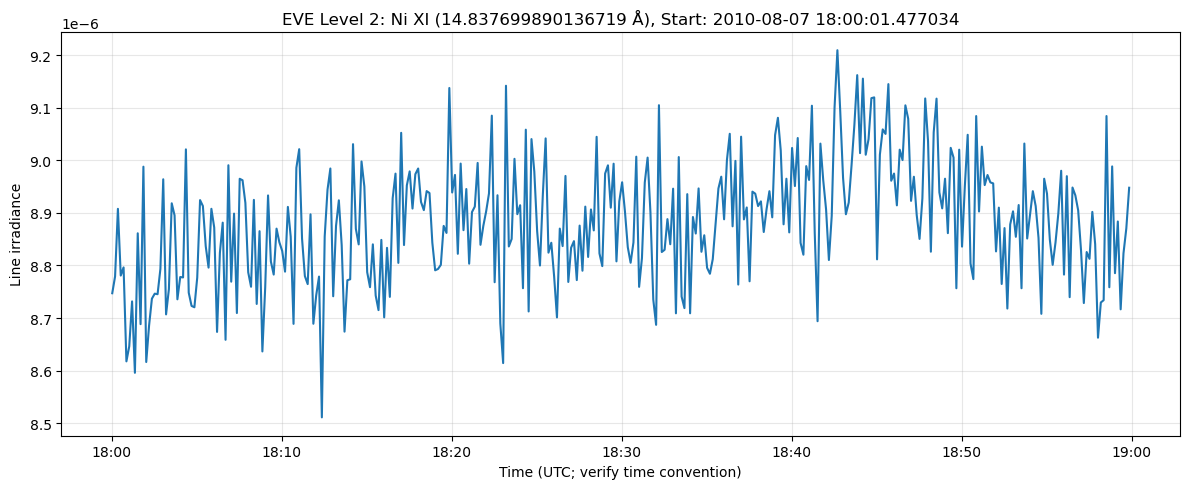

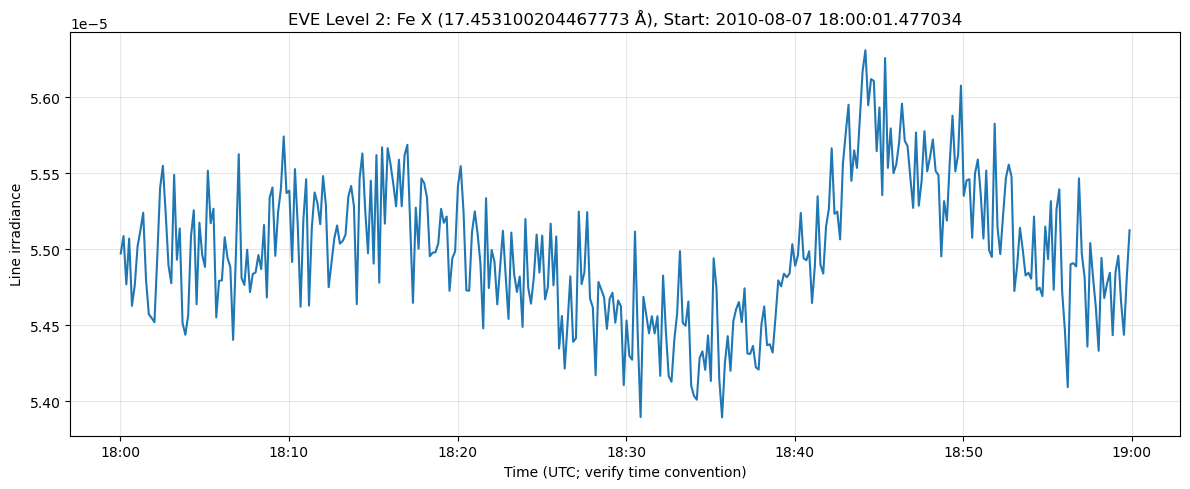

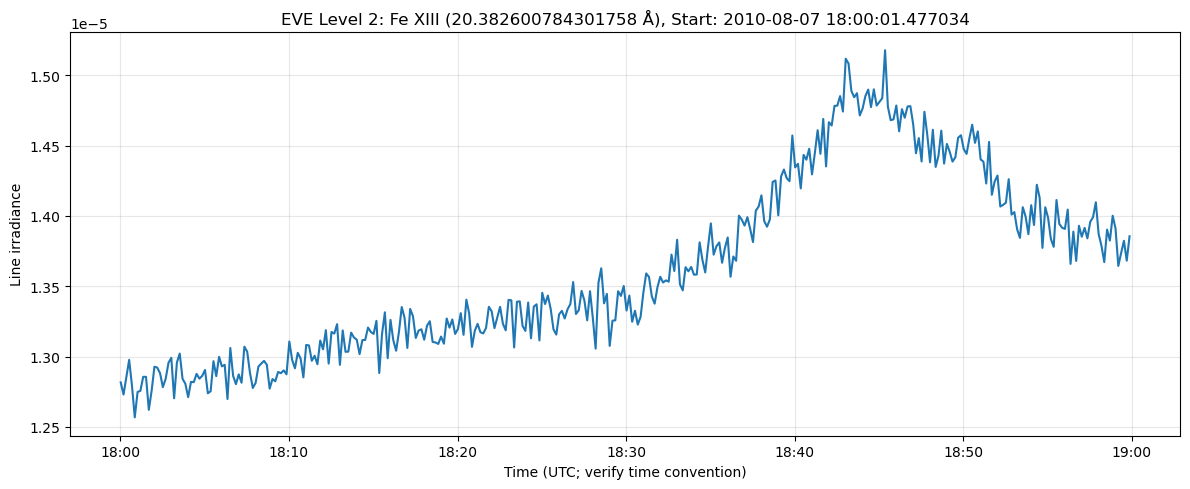

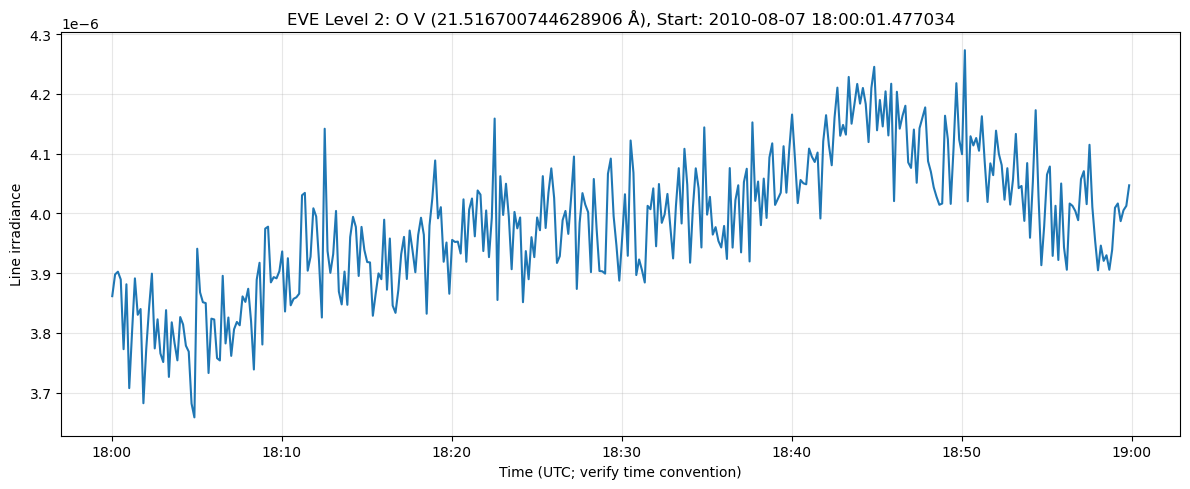

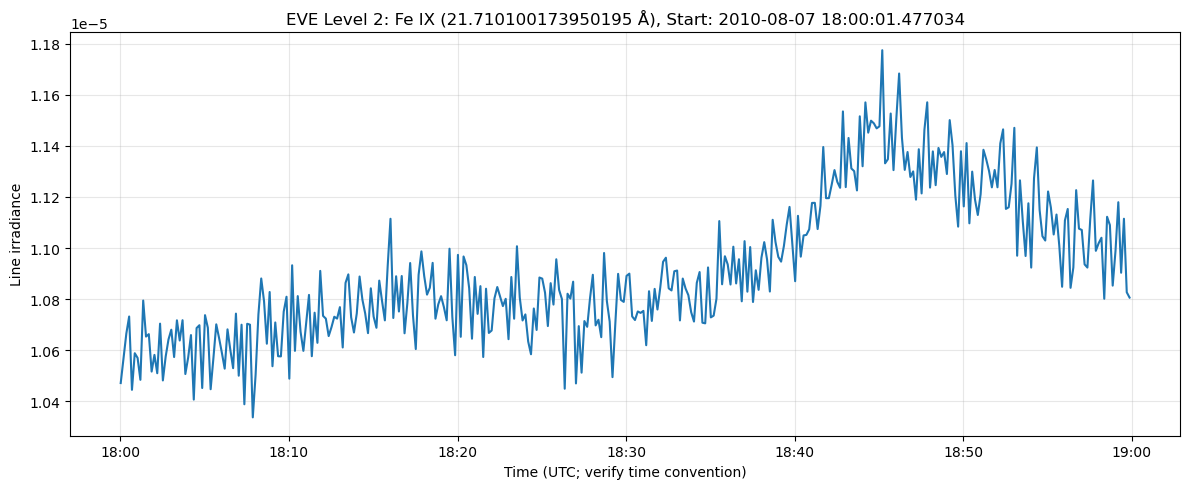

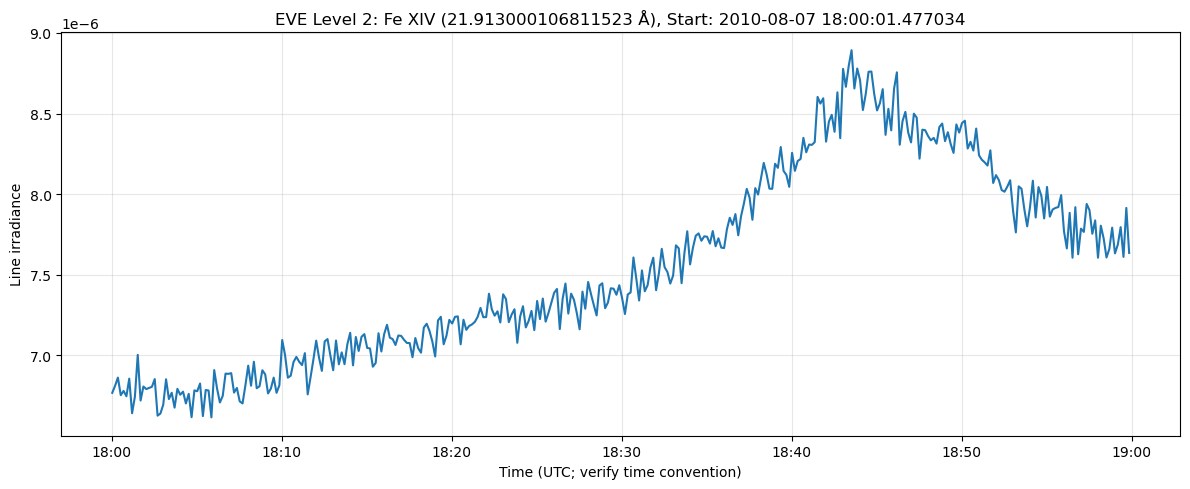

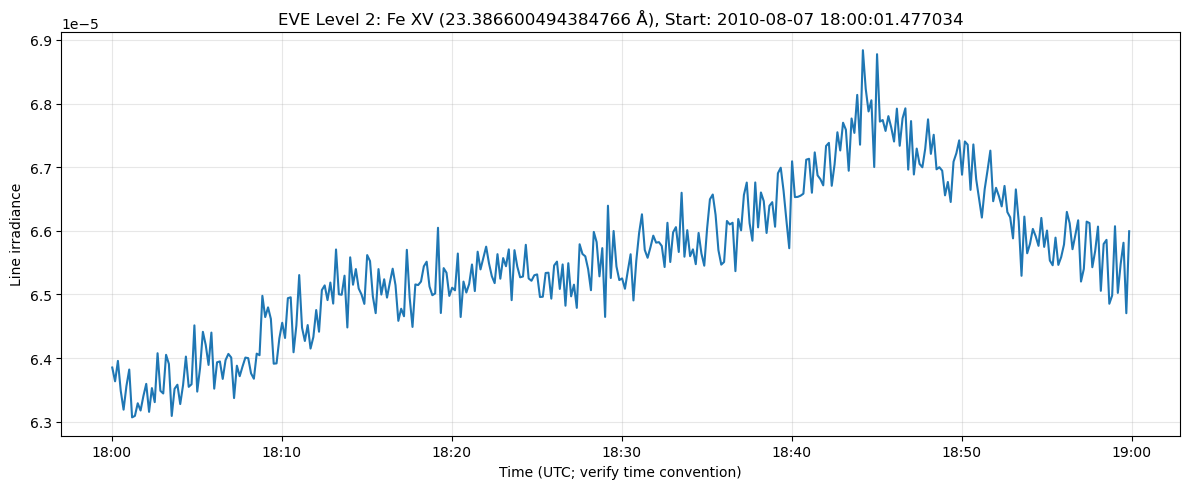

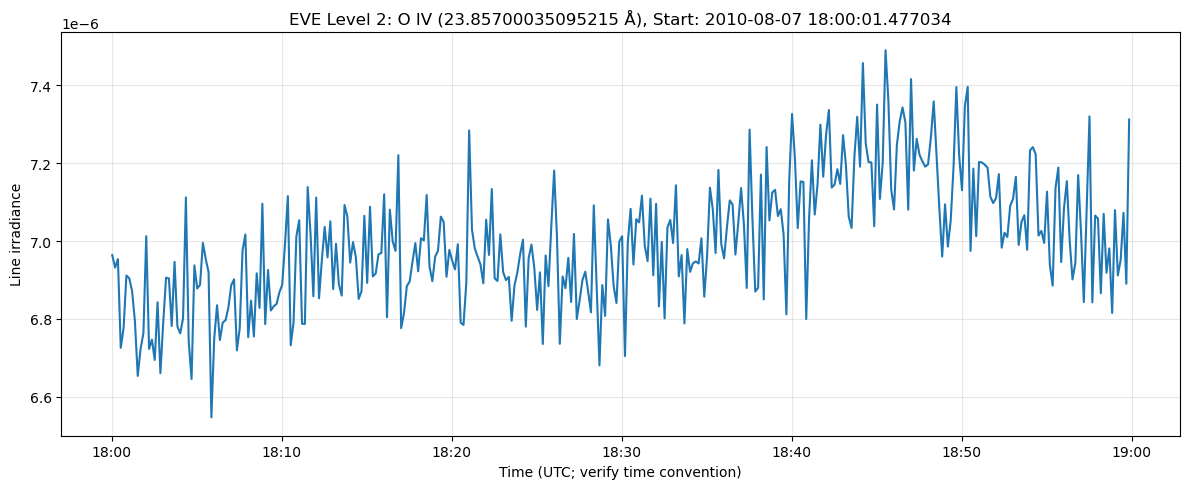

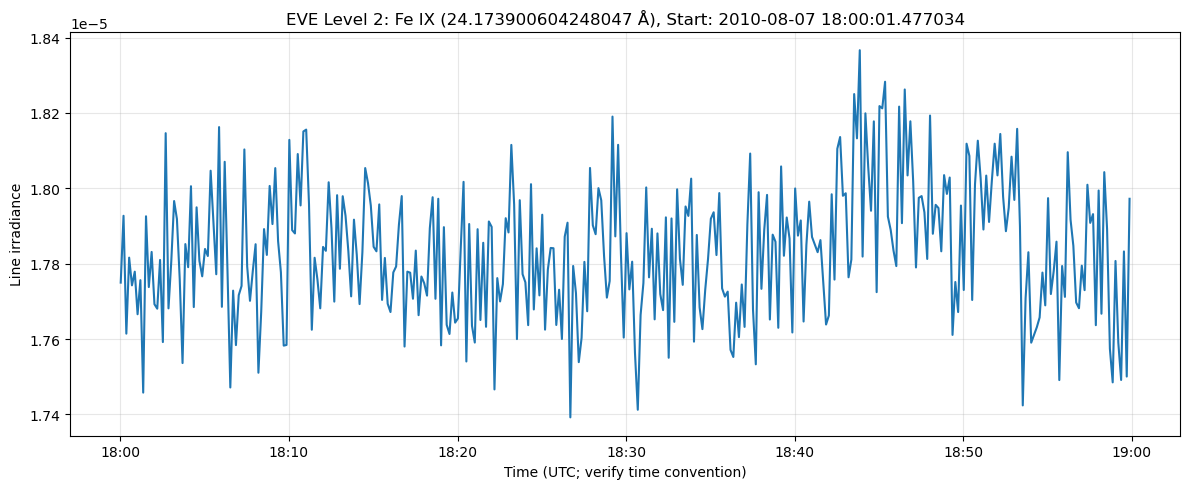

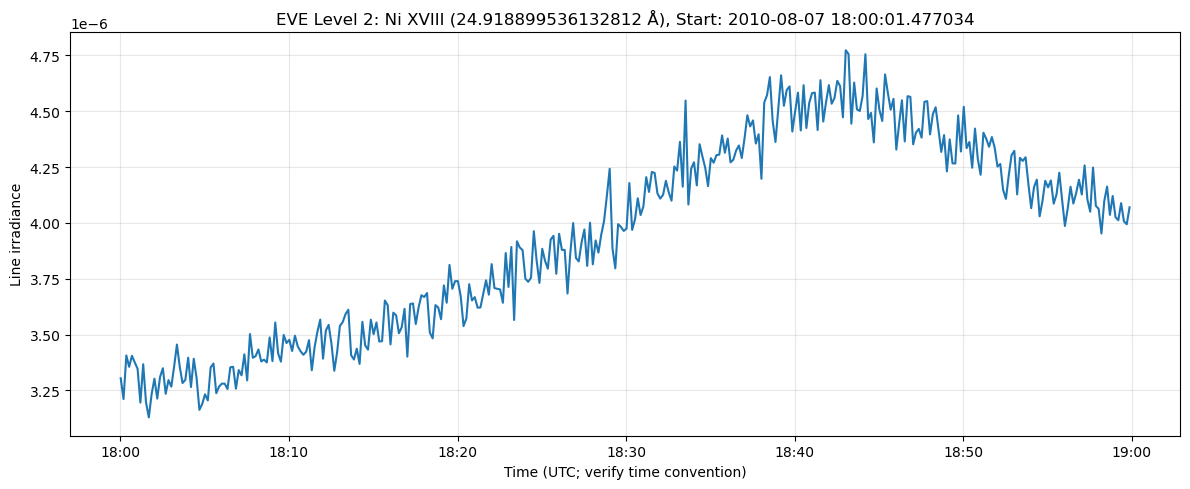

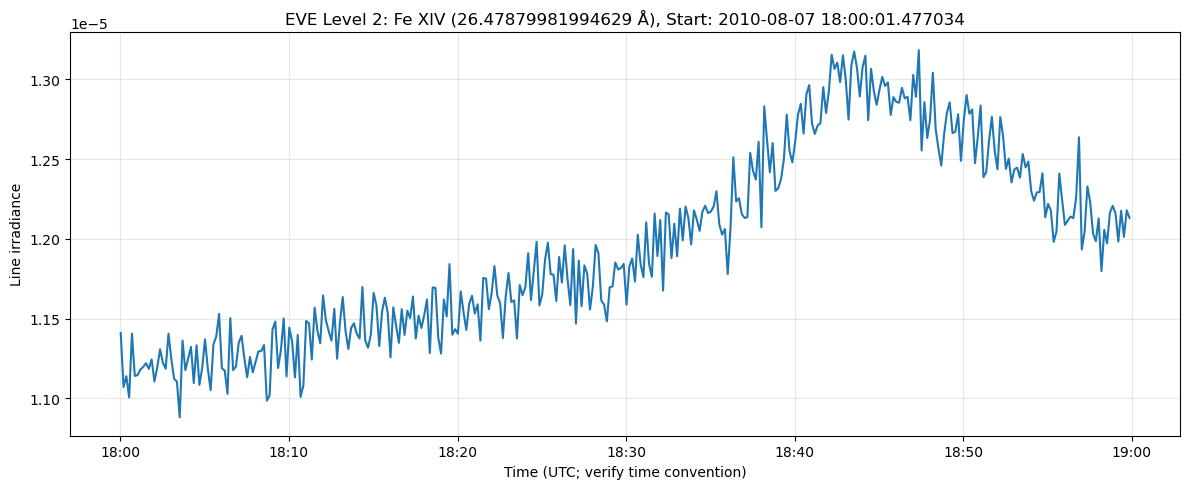

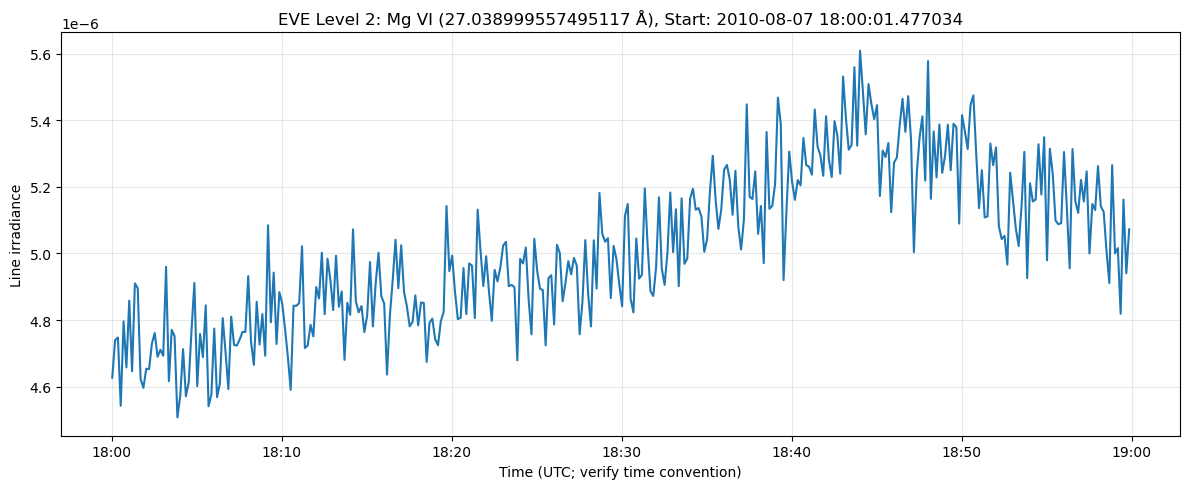

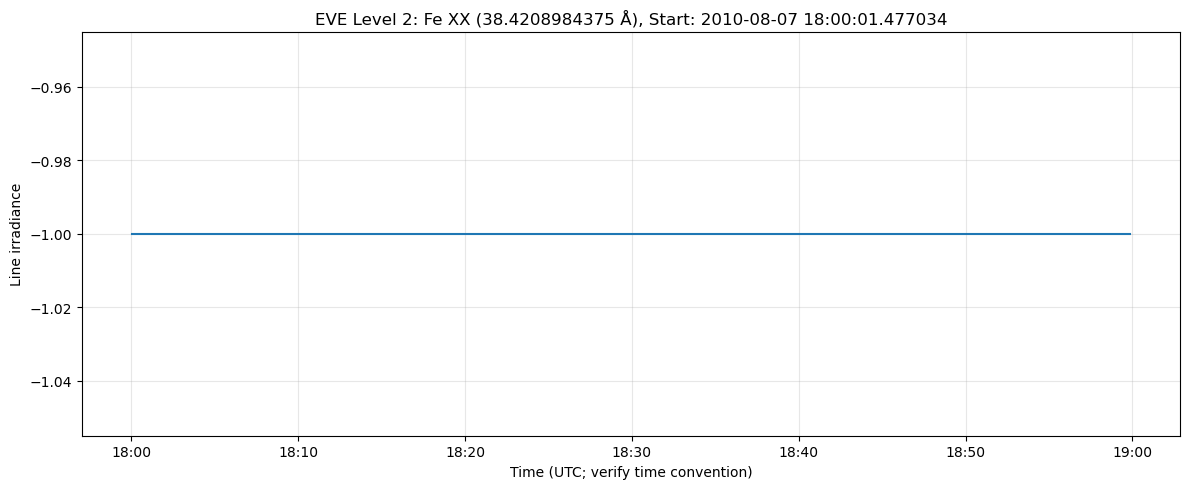

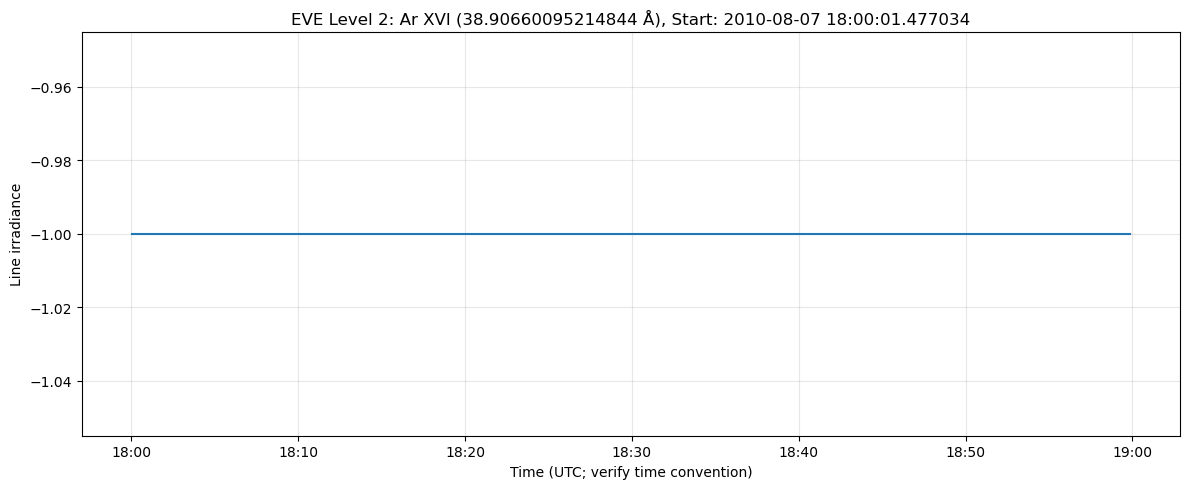

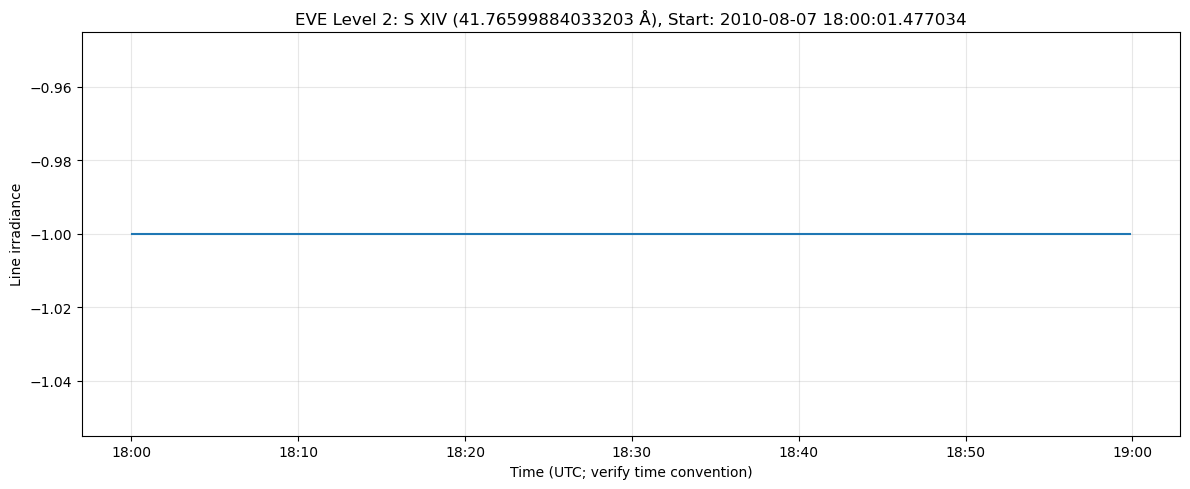

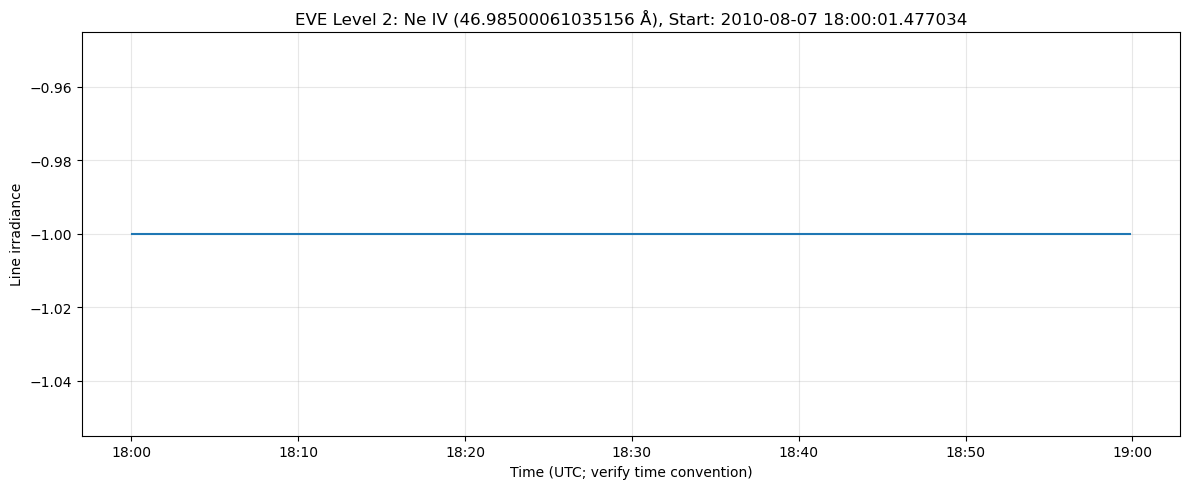

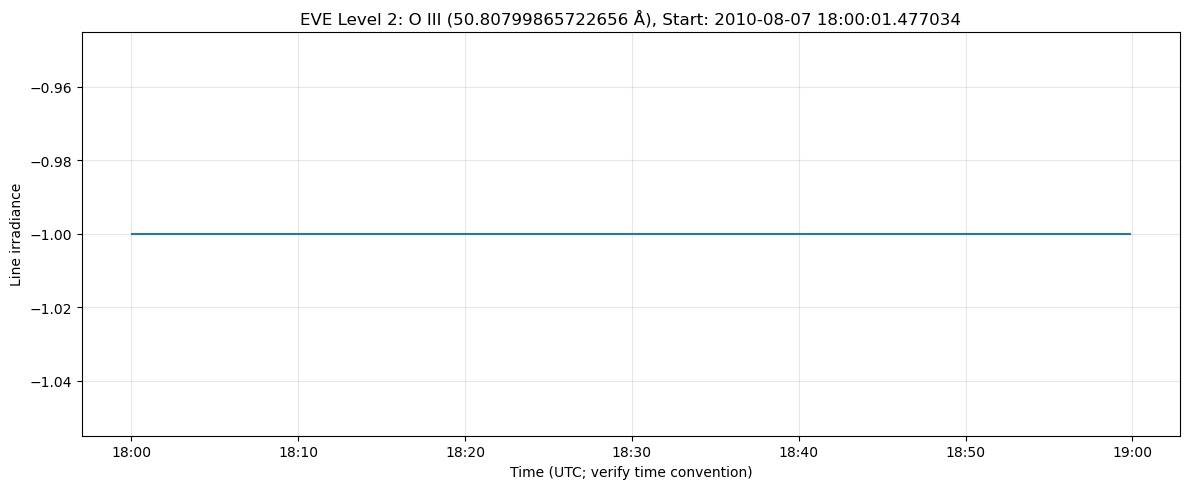

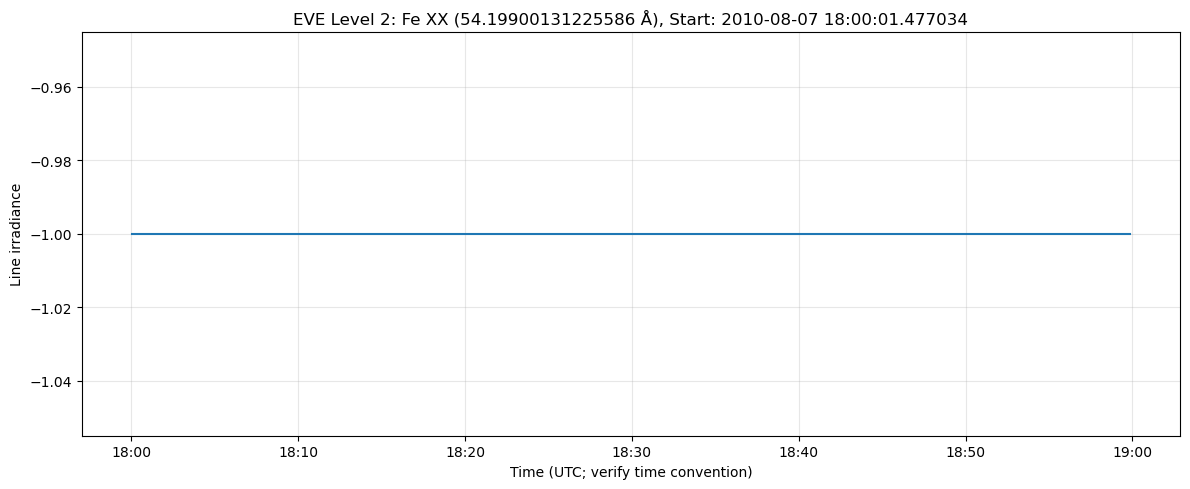

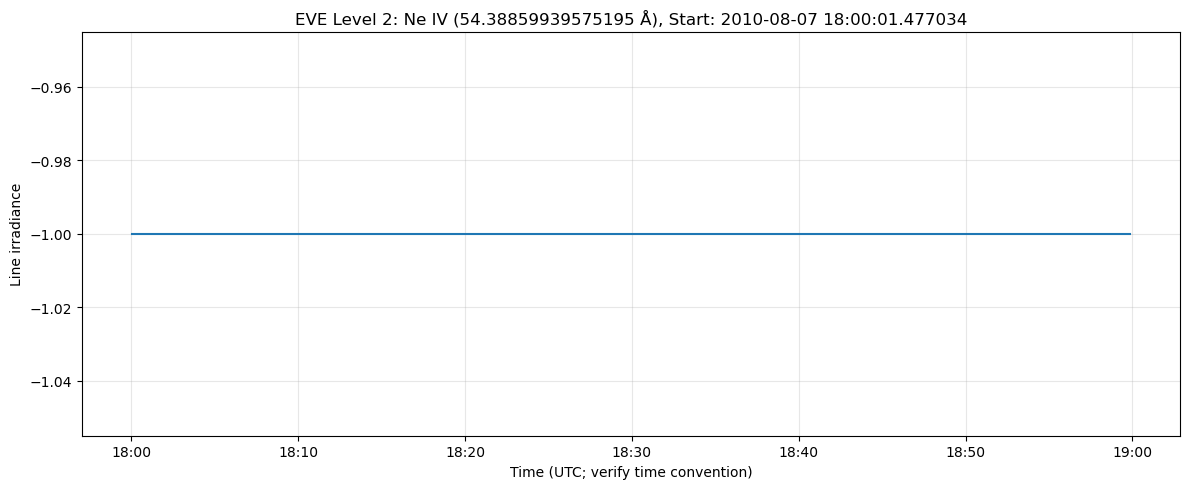

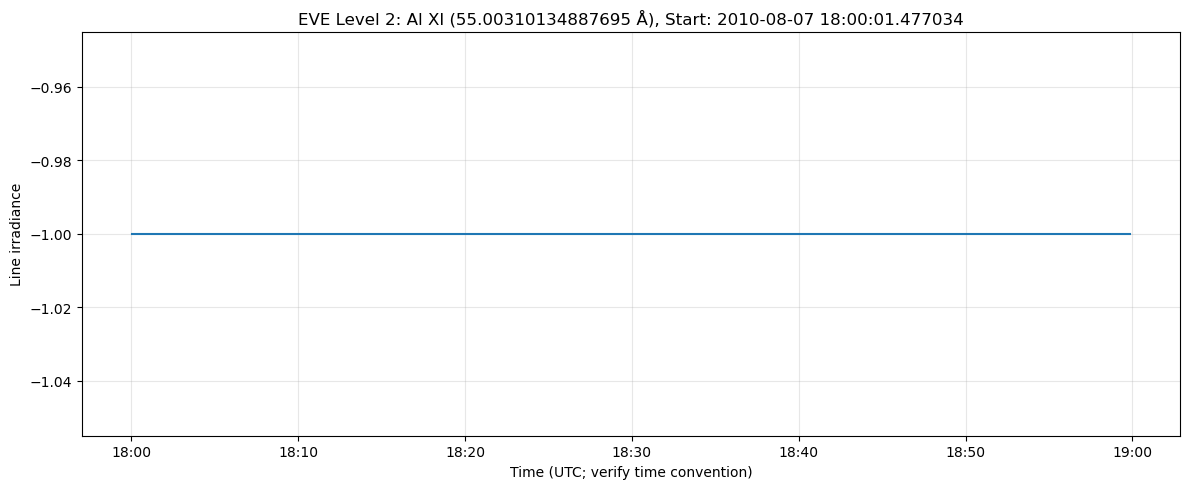

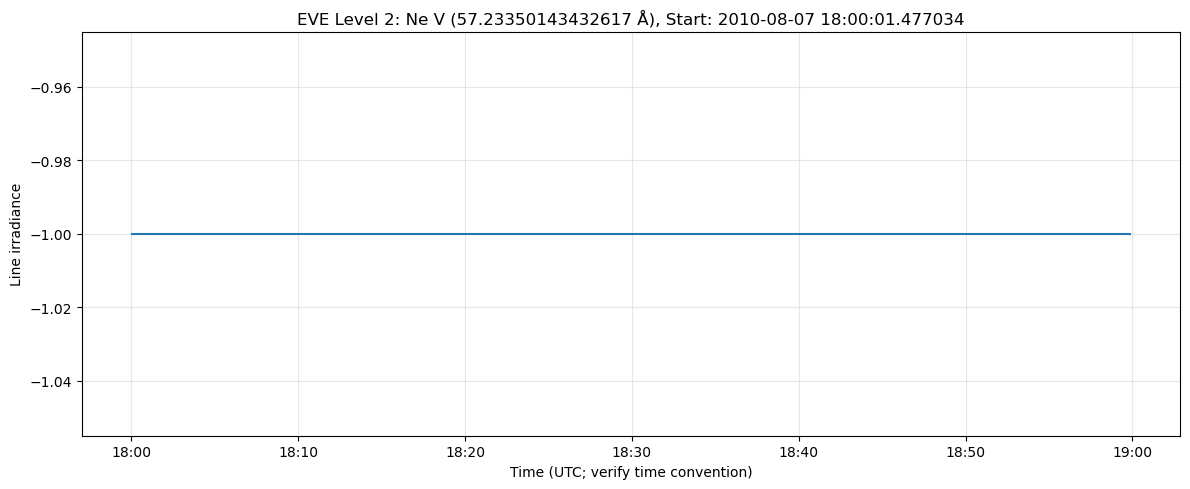

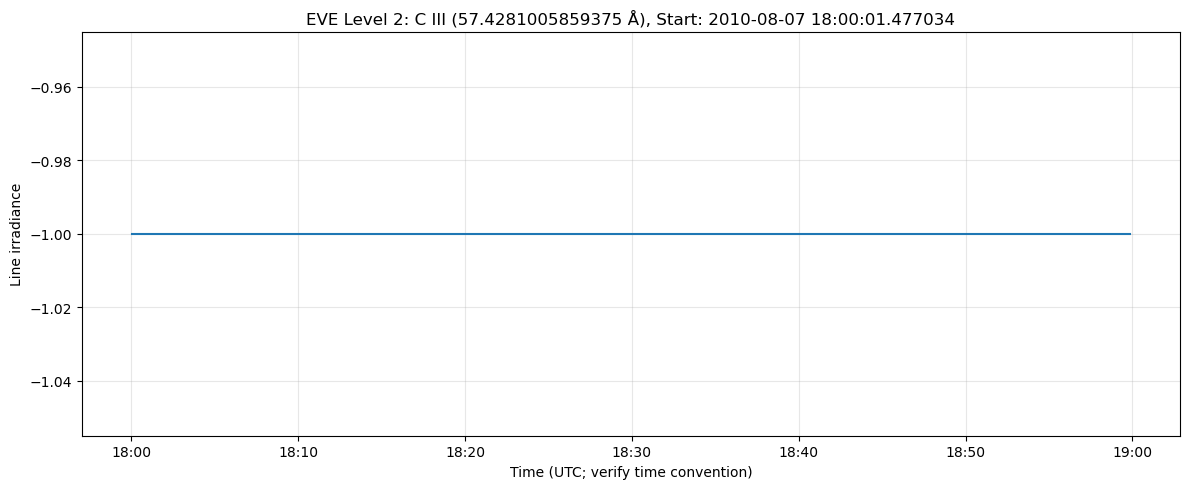

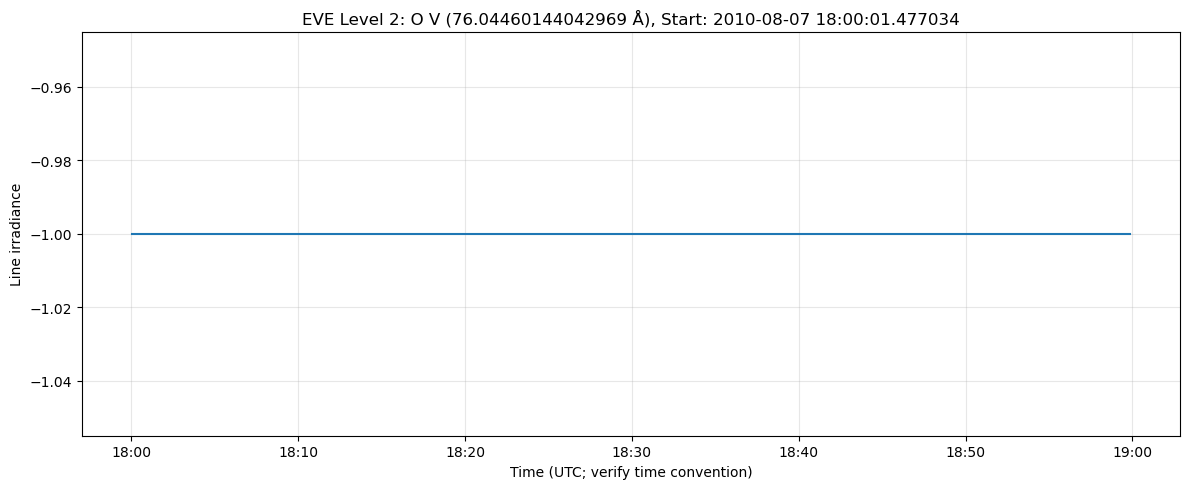

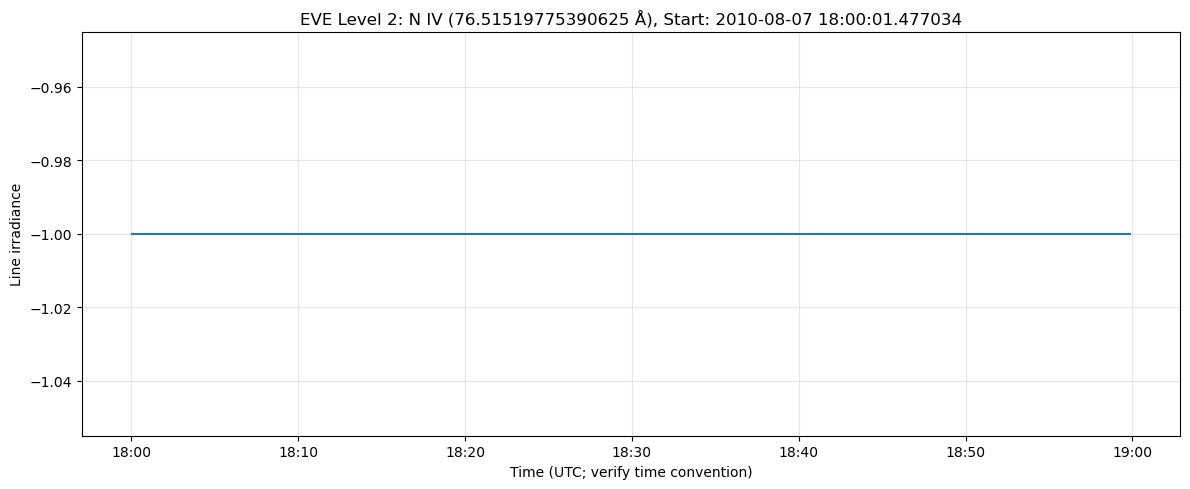

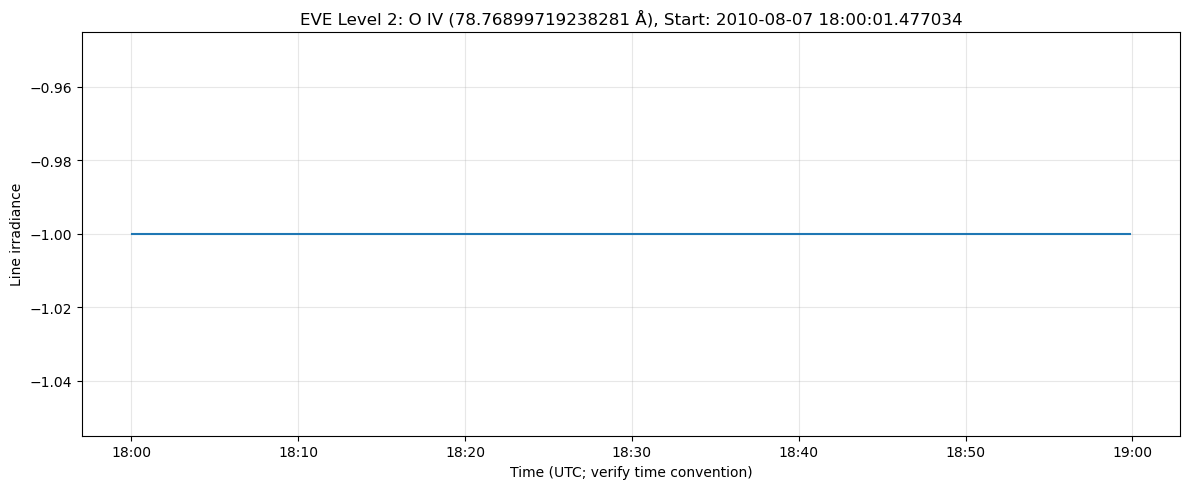

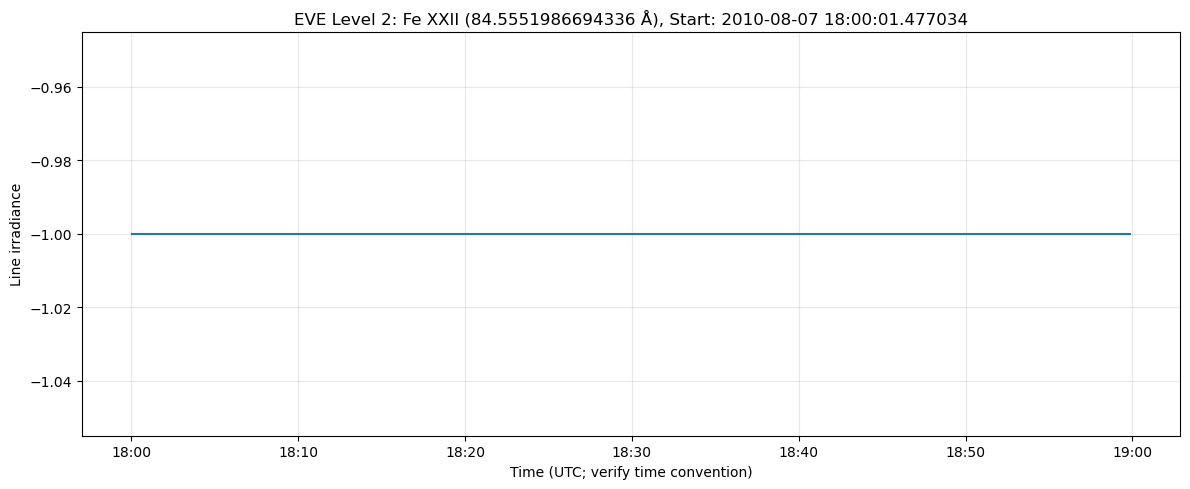

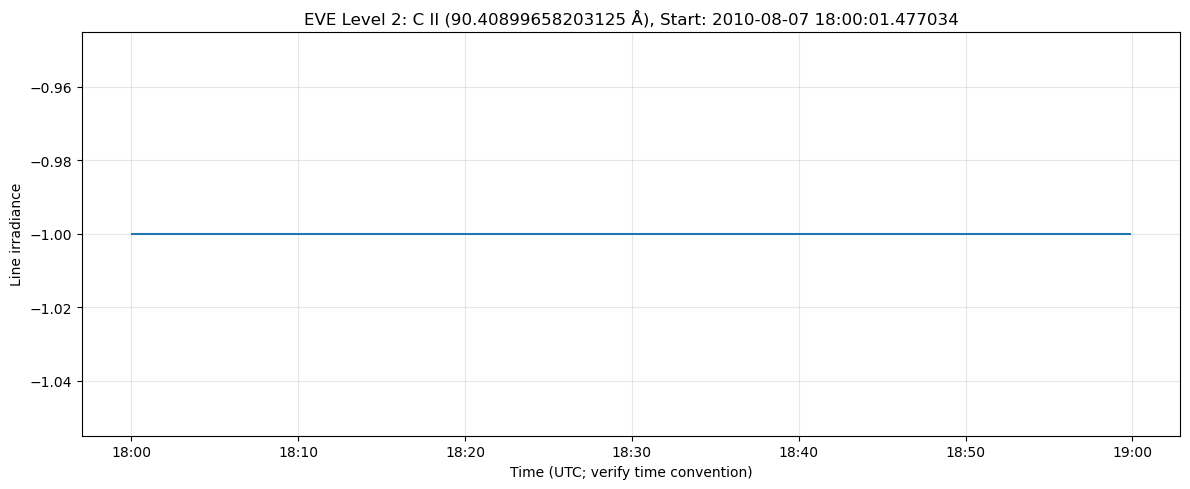

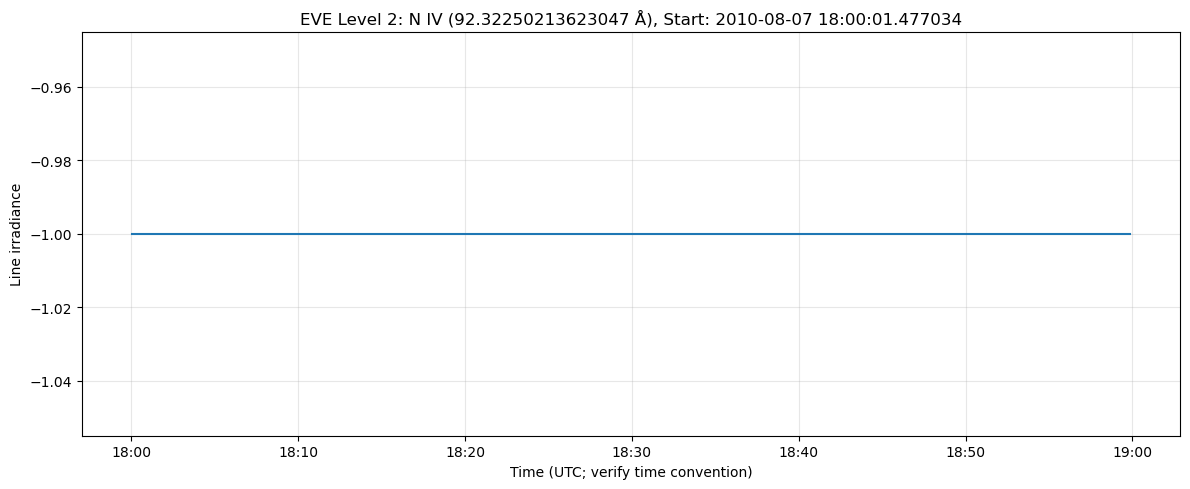

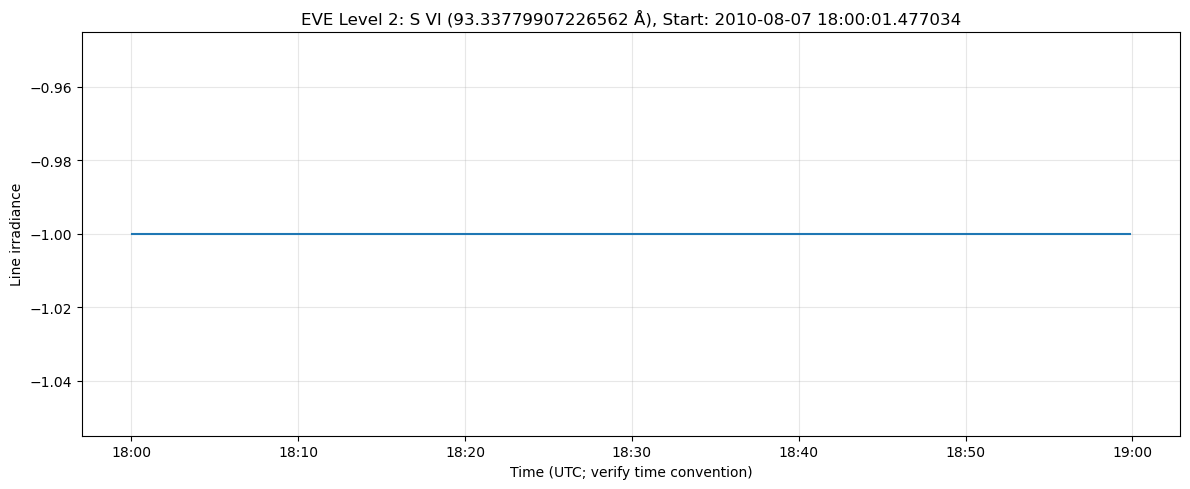

In [2]:


filename = "EVL_L2_files/"+"EVL_L2_2010219_18_008_01.fit.gz"

with fits.open(filename) as hdul:
    data = hdul["LinesData"].data
    meta = hdul["LinesMeta"].data

    line_irradiance = np.asarray(data["LINE_IRRADIANCE"])
    year_doy = data["YYYYDOY"]
    sod = data["SOD"]
    #for i, line in enumerate(meta):
     #   print(i, line["NAME"], line["WAVE_CENTER"]) ##to see the emission lines

# Convert YYYYDOY and SOD to datetime
times = []
for yd, seconds in zip(year_doy, sod):
    year = int(yd) // 1000
    doy = int(yd) % 1000
    dt = datetime(year, 1, 1) + timedelta(
        days=doy - 1, seconds=float(seconds)
    )
    times.append(dt)
for i in range(70):
    # Choose an emission line
    line_index = i
    
    plt.figure(figsize=(12, 5))
    plt.plot(times, line_irradiance[:, line_index])
    plt.xlabel("Time (UTC; verify time convention)")
    plt.ylabel("Line irradiance")
    plt.title(
        f"EVE Level 2: {meta[line_index]['NAME']} "
        f"({meta[line_index]['WAVE_CENTER']} Å)"
        f", Start: {times[0]}"
    )

    #plt.axvline(times[100])
    #plt.axvline(times[200])

    
    plt.gca().xaxis.set_major_formatter(
        mdates.DateFormatter("%H:%M")
    )
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()